In [1]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))

import mdtraj as md
import os, sys
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib
import numpy as np
from functools import reduce, partial
import scipy
from importlib import reload
from cycler import cycler
from itertools import chain
from typing import Dict, List, Tuple
import warnings
warnings.filterwarnings("ignore")


# source modules and classes being developed 
from writhe_tools.writhe import (Writhe,
                                 get_segments)


from writhe_tools.plots import (
                                proj2d,
                                fes2d,
                                get_color_list,
                                box_plot,
                                build_matrix_boxplot_grid,
                                lineplot1D,
                                annotated_matrix_plot
)

from writhe_tools.tcca import CCA, tCCA


from writhe_tools.stats import Kmeans, rotate_points, acf, pmf, cross_correlation, plot_cross_correlation


from writhe_tools.md_tools import (ResidueDistances,
                                   get_residues,
                                   calc_sa,
                                   traj_slice,
                                   load_traj,
                                   plot_distance_matrix,
                                   residue_distances,                                 
                                   to_contacts
                                    )


from writhe_tools.utils import (lsdir,
                                group_by,
                                reindex_list,
                                contiguous_bool,
                                to_numpy,
                                num_str,
                                load_dict,
                                save_dict,
                                product
                                )

from writhe_tools.writhe_numba import pbc_correct




fes2d_args = dict(
      cmap="coolwarm",
      bins=55,
      n_contours=8,
      contour_lines=True,
      alpha_lines=0.35,
      alpha_contours=0.6,
      mask=False,
      scatter=True,
      scatter_alpha = .15,
      scatter_size=.05,
      scatter_stride=50,
      scatter_max=.35,
      scatter_min=.15,
      scatter_cmap="coolwarm",
      hide_ax=False,
      extend_border=0.1,
    )



def fill_1d(x, values, indices):
    x[indices] = values
    return x

def fill(x, index, val):
    x[:, index] = val
    return x

def prod(vectors, sum_=False):
    if sum_:
        vectors = [v.sum(axis=-1) for v in vectors]
    return reduce(np.multiply, vectors)

split = partial(np.array_split, indices_or_sections=2, axis=-1) 

ternary_bool = lambda distances : prod([to_contacts(i, 1).any(1) for i in split(distances)])

isin_index = lambda x, y : np.where(np.isin(x, y))[0]




def bootstrap(data: np.ndarray,
              confidence_level: float = 0.68,
              n_resamples: int = 500,
              lower_upper: bool = False,
              method: str = "percentile") -> Tuple[float, float]:
    """
    Bootstrap binary data to get the mean and an intentionally wide error estimate.

    Parameters:
        data: binary array of 0s and 1s
        confidence_level: typically 0.99 for wider intervals
        n_resamples: lower values increase variability (default 500)
        method: use 'percentile' to produce wider CIs

    Returns:
        mean: estimated mean of the binary array
        error: half-width of the confidence interval
    """

    res = scipy.stats.bootstrap((data,), statistic=np.mean,
                    confidence_level=confidence_level,
                    n_resamples=n_resamples,
                    method=method,
                    random_state=0)

    mean = np.mean(data) if data.ndim == 1 else data.mean(0)
    error = [res.confidence_interval.low, res.confidence_interval.high] if lower_upper\
            else (res.confidence_interval.high - res.confidence_interval.low) / 2
    if data.ndim > 1:error = np.stack(error)
    
    return mean, error


from pyblock.blocking import reblock, find_optimal_block
from collections import Counter
def block_error(x: np.ndarray, lower_upper: bool = False):
    """
    x : (N, d) numpy array with d features and N measurements
    """
    n = x.shape[0]
    blocks = reblock(x.T)
    optimal_indices = np.asarray(find_optimal_block(n, blocks))
    isnan = np.isnan(optimal_indices)
    #mode = Counter(optimal_indices[~isnan].astype(int)).most_common()[0][0]
    optimal_indices[isnan] = -1 # biggest block
    optimal_indices=optimal_indices.astype(int)
    #op
    #print(optimal_indices[0])
    if x.ndim == 1:
        return lu_from_error(x.mean(), blocks[optimal_indices[0]].std_err.item()) if lower_upper else\
                (x.mean(), blocks[optimal_indices[0]].std_err.item())
    else:
        return lu_from_error(x.mean(0), np.asarray([blocks[i].std_err[j] for j, i in enumerate(optimal_indices.astype(int))]))\
                if lower_upper else (x.mean(0), np.asarray([blocks[i].std_err[j] for j, i in enumerate(optimal_indices.astype(int))]))

def lu_from_error(mean, error):
    if all(isinstance(i, (float, int)) for i in (mean, error)):
        mean, error = [mean], [error]
    return mean, np.array([[mu - err, mu + err] for mu, err in zip(mean, error)]).T

# convenience (hard coded to 2 monomers) function to combine stats and prop error for averages to be taken over both monomers
def monomer_aggr_stats(x, 
                       error:callable=block_error, 
                       lower_upper: bool = False, 
                       fill_bool:np.ndarray=None):
    # compue mean and error over both monomers, aggregate, fill zeros for plotting, give lower, upper errors or absolute error
    ave, err = error(x, lower_upper=False)
    ave = np.add.reduce(split(x.mean(0))) / 2
    err = np.linalg.norm(err.reshape(2, -1), axis=0) / 2
    
    if lower_upper:
        # very simple error propogation here (arguably too simple)
        err = lu_from_error(ave, err)[-1]                   
        if fill_bool is not None:
            ave = fill_1d(np.zeros(len(fill_bool)), ave, fill_bool)
            err = np.stack([fill_1d(np.zeros(len(fill_bool)), i, fill_bool) for i in err])

        return ave, err


    return (ave, err) if fill_bool is None else [fill_1d(np.zeros(len(fill_bool)), i, fill_bool) for i in [ave, err]]


#block_error(np.arange(10000), lower_upper=False)
path = "/data/r1r2"
epi_dir = f"{path}/epi002"
apo_dir = f"{path}/apo"
cam_dir = f"{path}/cam1"
paths = [apo_dir, epi_dir, cam_dir]
labels = ['APO', 'EPI-002', '1aa']

protein_files = ['/data/r1r2/apo/protein.100us.dcd',
                 '/data/r1r2/epi002/protein.100us.dcd',
                 '/data/r1r2/cam1/protein.85us.dcd']


ligand_files = [lsdir(i, keyword=['dcd', 'ligand'], exclude=['wrap'], match=all)[0] for i in paths[1:]]
protein_pdb = '/data/r1r2/epi002/R2_dimer.pdb'
ligand_pdbs = [
               '/data/r1r2/epi002/R2_dimer.epi002.rename.pdb',
               '/data/r1r2/cam1/protein.ligand.pdb',
               ]
helix_pdb = '/data/r1r2/monomer_r1r2_helix.pdb'

trunc = .3
pre_trunc = .3
state_width = .8
state_font_scale = 1.5
codes = np.array(list(md.load(protein_pdb).top.to_fasta()[0]))[:24]


# Computations

In [280]:
# protein only calculations

label = '1aa'
ca_selection = md.load(protein_pdb).top.select('name CA')
sequence, ca_index = get_residues(md.load(protein_pdb))
# 1 letter codes for the monomer sequence (just 1)

unitcell_lengths = traj=md.load(protein_files[2], top=protein_pdb).unitcell_lengths


ca_distances = ResidueDistances(index_0=np.arange(24),
                                index_1=np.arange(24, 48),
                                traj=md.load(protein_files[2], top=protein_pdb, atom_indices=ca_selection)
                               )

# dimer events from ca_distances
dimer = ca_distances.contacts(1).any(1)
dimer_events = contiguous_bool(bools=dimer)
dimer_lengths = 0.24 * np.fromiter(map(len, dimer_events), float) # scale by physical time

# sort by event length
sort = dimer_lengths.argsort()[::-1]
dimer_events = reindex_list(dimer_events, sort)
dimer_lengths = dimer_lengths[sort]

# structural features
sa = np.stack([calc_sa(md.load(protein_files[2], top=protein_pdb, atom_indices=j), helix_pdb) for j in split(ca_selection)])

dssp = np.where(md.compute_dssp(traj=md.load(protein_files[1], top=protein_pdb)) == 'H', 1, 0)[:, ca_index].reshape(-1, 2, 24
                                                                                                                   ).transpose(1, 0, 2)
writhe = Writhe(xyz=md.load(protein_files[2], top=protein_pdb, atom_indices=ca_selection).center_coordinates().xyz)

#Writhe class will assume the whole protein is one chain be default - have to feed the segments manually to 
# result the fact that the two chains aren't connected 
# we are really just preventing the the class from making a single nonsense segment between the end and start residues of the two monomers
segments = np.concatenate([get_segments(index0=np.arange(24)),
                           get_segments(index0=np.arange(24, 48)),
                           get_segments(index0=np.arange(24), index1=np.arange(24, 48))
                          ])

writhe_features = writhe.compute_writhe(segments=segments,
                                        cuda=True,
                                        store_results=False,
                                        lengths=unitcell_lengths,
                                        )['writhe_features']

# dimensionality reduction
tcca = tCCA(writhe_features, lag=10, dim=2,).fit()

# compute the projection and then 
proj = tcca.transform(writhe_features); 
#align to a reference because eigenvects might have flipped sign - NOT NEEDED, JUST FOR ASTHETIC (transformation is trivial)
proj = rotate_points(np.load(lsdir(paths[2], keyword='writhe_tcca_lag_')[0])[1:, :2],
                                                             proj, so3=False)

# to cluster with Kmeans
#dtraj, frames_cl = Kmeans(proj, n_clusters=10, n_dim=2)

# Kmeans isn't deterministic, so we use a pre computed clustering to keep consistency with reported values

## WARNING - MUST HAVE REFERNECE AVAILABLE FOR THIS TO WORK - CAN JUST COMMENT THIS OUT AND RECLUSTER USING LINES ABOVE
#macrostates = load_dict('density_clusters.pkl')[2]; frames_cl = group_by(macrostates)
macrostates = np.load('1aa_cg_macrostates.npy'); frames_cl = group_by(macrostates)
centroids = group_by(macrostates, proj, reduction = partial(np.mean, axis = 0))


/home/t/miniconda3/envs/writhe/lib/python3.10/site-packages/mdtraj/core/selection.py:397: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse_result = self.expression.parseString(selection, parseAll=True)
/home/t/miniconda3/envs/writhe/lib/python3.10/site-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
/home/t/miniconda3/envs/writhe/lib/python3.10/site-packages/mdtraj/core/selection.py:397: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse_result = self.expression.parseString(selection, parseAll=True)
/home/t/miniconda3/envs/writhe/lib/python3.10/site-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
/home/t/miniconda3/envs/writhe/lib/python3.10/site-packages/mdtraj/core/selection.py:397: PyparsingDeprecationWarning: 'parseString'

macrostates = np.load('1aa_macrostates_13.npy'); frames_cl = group_by(macrostates)
centroids = group_by(macrostates, proj, reduction = partial(np.mean, axis = 0))

macrostates = load_dict('density_clusters.pkl')[2]; frames_cl = group_by(macrostates)
#macrostates = np.load('1aa_cg_macrostates.npy'); frames_cl = group_by(macrostates)
centroids = group_by(macrostates, proj, reduction = partial(np.mean, axis = 0))

# binding explains future folding more than folding explains future binding (biased towards folding upon binding more than conformational selection)

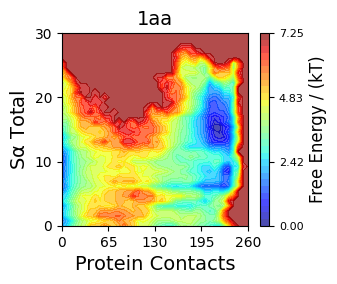

In [9]:
def sigmoid(x, shift=1, scale=1):
    return 1 - 1 / (1 + np.exp(-scale * (x - shift)))



extent = ((0, 400), (0, 30))
fes2d(
      sigmoid(ca_distances.distances).sum(-1),
      sa.sum((0,-1)),
      ylabel=r'S$\alpha$'+" Total",
      xlabel="Protein Contacts",
      bins=40,
      tick_decimals=0,
      title=label,
      mask=False,
      contour_lines=False,
      alpha_contours=.7,
      alpha_lines=.1,
      mask_thresh=5,
      n_contours=30,
      nxticks=5, 
      extent=((0, 260), (0, 30)),
    figsize=(3, 2.5))
#plt.savefig(f'./{label}_helix_contact_fes', dpi = 1000, bbox_inches = 'tight')

In [3]:
#new tools for ligand interactions but general to computing Aromatics and Hbonds
from tools import Aromatics, HBonds, rm_index, t_stack, pi_stack
from writhe_tools.md_tools import canonical_residues

index=1 # first ligand trajectory (1aa is second one, e.i (index = 1))
# protein-ligand computations
sequence, ca_index = get_residues(md.load(ligand_pdbs[index]))
ligand_name = 'LIG1'
ligand_index = isin_index(sequence, ligand_name)

ligand_distances = ResidueDistances(traj=md.load(ligand_files[index], top=ligand_pdbs[index]), index_0=ligand_index, index_1=ca_index)

#ternary events from ligand distances (closest-heavy, contact cut-off of 0.6
ternary = np.multiply.reduce([i.any(1) for i in split(ligand_distances.contacts(0.6))])
ternary_events = contiguous_bool(bools=ternary)
ternary_lengths = 0.24 * np.fromiter(map(len, ternary_events), float) # scale by physical time

# sort by event length
sort = ternary_lengths.argsort()[::-1]
ternary_events = reindex_list(ternary_events, sort)
ternary_lengths = ternary_lengths[sort]

######################### ligand interactions ######################################################

########### Aromatic stacking ############

aro = Aromatics(md.load(ligand_files[index], top=ligand_pdbs[index]))
sequence, ca_index = get_residues(md.load(ligand_pdbs[index]))
aro_bool = np.isin(rm_index(sequence[ca_index])[:24], np.array(['TYR', 'HIS', 'TRP']))
# angles has [theta,phi,distance] in the last dimension
angles, pair_groups, pairs = aro.angles_between_groups(['LIG'], ['TYR', 'HIS', 'TRP'])
# apply cut offs, aggregate (logical OR) over residue-ligand pairs for all rings (two on the ligand here)
stacking = group_by(pair_groups, (t_stack(*angles.T) | pi_stack(*angles.T)).T , partial(np.any, axis=0)).T
#print('Aromatic stacking pairs','\n', pairs)
# fill up an array of zeros so 
#stacking = fill(np.zeros((ligand_distances.distances.shape[0], 24), stacking, aro_bool)

########### Hbonds ########### 

not_proline = ~np.isin(rm_index(sequence[ca_index]), ['PRO']) # not needed here
hbond_class = HBonds(md.load(ligand_files[index], top=ligand_pdbs[index]))
groups = [canonical_residues, ['LIG']] # get ligand as donor and acceptor in the next line by interchanging args ([::-1])
# angles also has distance inside last dim
angles = [hbond_class.angles_between_groups(donor_group=i, acceptor_group=j) for i,j in zip(groups, groups[::-1])]
# this part is really optional if one seek a residue level description
hbonds = [hbond_class.hbonds_between_groups(angles=i)[0] for i in angles]
# the hbonds class returns a tuple with (hbond bools, groupings of hbonds, indexed pairs with a sequence index
# and an additional index in cases where a residue or ligand has multiple acceptor / donor sites.
# internally, the class will group interactions at the residue level using logical OR to conserve binary
#print('protein donor pairs\n', angles[0][-1], 'ligand donor pairs\n', angles[1][-1])
# if proline is in sequence or the ligand can't function as a donor or acceptor, code will have to be ajusted accordingly
# here, the ligand can be both a donor and acceptor and there's no proline, so the post hoc sorting / indexing / filling, etc is not needed 
# hbonds[0] = fill(np.zeros_like(hbonds[1]), not_proline, hbonds[0])
# for simplicity sake, we're just going to redefine 'hbonds' as the total
hbonds =  np.logical_or.reduce(hbonds).T # lig as donor OR acceptor - gives unconditional interaction probability when mean is taken over fames 
print(f'max(Total HBonds) before taking the mean : {hbonds.max()}')

########### hydrophobic ##############

# to simplify things, we can just remove all of the atoms except carbon and then use nearest heavy (defaul of ResidueDstances)
traj = md.load(ligand_files[index], top=ligand_pdbs[index],
               atom_indices = md.load(ligand_pdbs[index]).top.select('type C'),
               stride=1)

# note that sequence is a dynamic variable that redefined based on the results of sliced trajectories as the indices will change
sequence = get_residues(traj)[0]

hphob_contacts = ResidueDistances(traj=traj,
                                 index_0=isin_index(rm_index(sequence), canonical_residues),
                                 index_1=isin_index(sequence, np.array(['EPI0', 'LIG1']))
                                ).contacts(0.6)

del traj # keep traj objs out of memory to avoid overflow, only keep calc results (still may have issues w/ mem)

###### End Interactions calculations ##############

max(Total HBonds) before taking the mean : True


atoms = np.array(list(md.load(ligand_pdbs[index]).top.atoms))
print('all possible acceptor atoms\n\n', atoms[np.array(list(hbond_class.acc_atom_to_res.keys()))],
      '\n\nall possible donor atoms\n\n',atoms[hbond_class.donors_array.flatten()].reshape(-1, 2))

 # Ligand Interactions plot

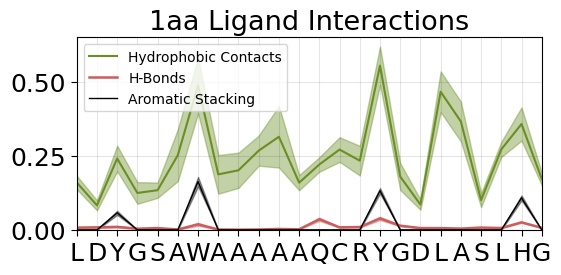

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(6, 2.5))
mu, err = monomer_aggr_stats(hphob_contacts, lower_upper=True)
scale = 1.5
lineplot1D(mu,
           color='olivedrab', fill_color='olivedrab', fill_alpha=.4,
           label='Hydrophobic Contacts', ax=ax, y1=err[0], y2=err[1], font_scale=scale)


mu, err = monomer_aggr_stats(hbonds, lower_upper=True)
lineplot1D(mu,
         color='indianred',
         fill_color='indianred',
         fill_alpha=.4,
         label='H-Bonds',
         ax=ax,
         alpha=1,
         lw=1.8,
         y1=err[0],
         y2=err[1],
         font_scale=scale
        )

mu, err = monomer_aggr_stats(stacking, lower_upper=True, fill_bool=aro_bool)
lineplot1D(mu,
         color='black',
         fill_color='black',
         y1=err[0],
         y2=err[1],
         fill_alpha=.4,
         ls='-',
         lw=1,
         label='Aromatic Stacking',
         ax=ax,
         #top_xticks=['', 395, 400, 405, 410, ''],
         xticks=codes[:24],
         xticks_rotation=0,
         title=f'{labels[1+index]} Ligand Interactions',
         font_scale=scale
        )

ax.set_ylim(0, .65)
#ax.grid(which='major', visible=True, axis='y')
ax.grid(which='major', color='black', linestyle='-', linewidth=0.8, axis='both', alpha=.1)
ax.legend()
fig.savefig(f'{paths[2]}/ligand_interactions.png', dpi=1000, bbox_inches='tight')

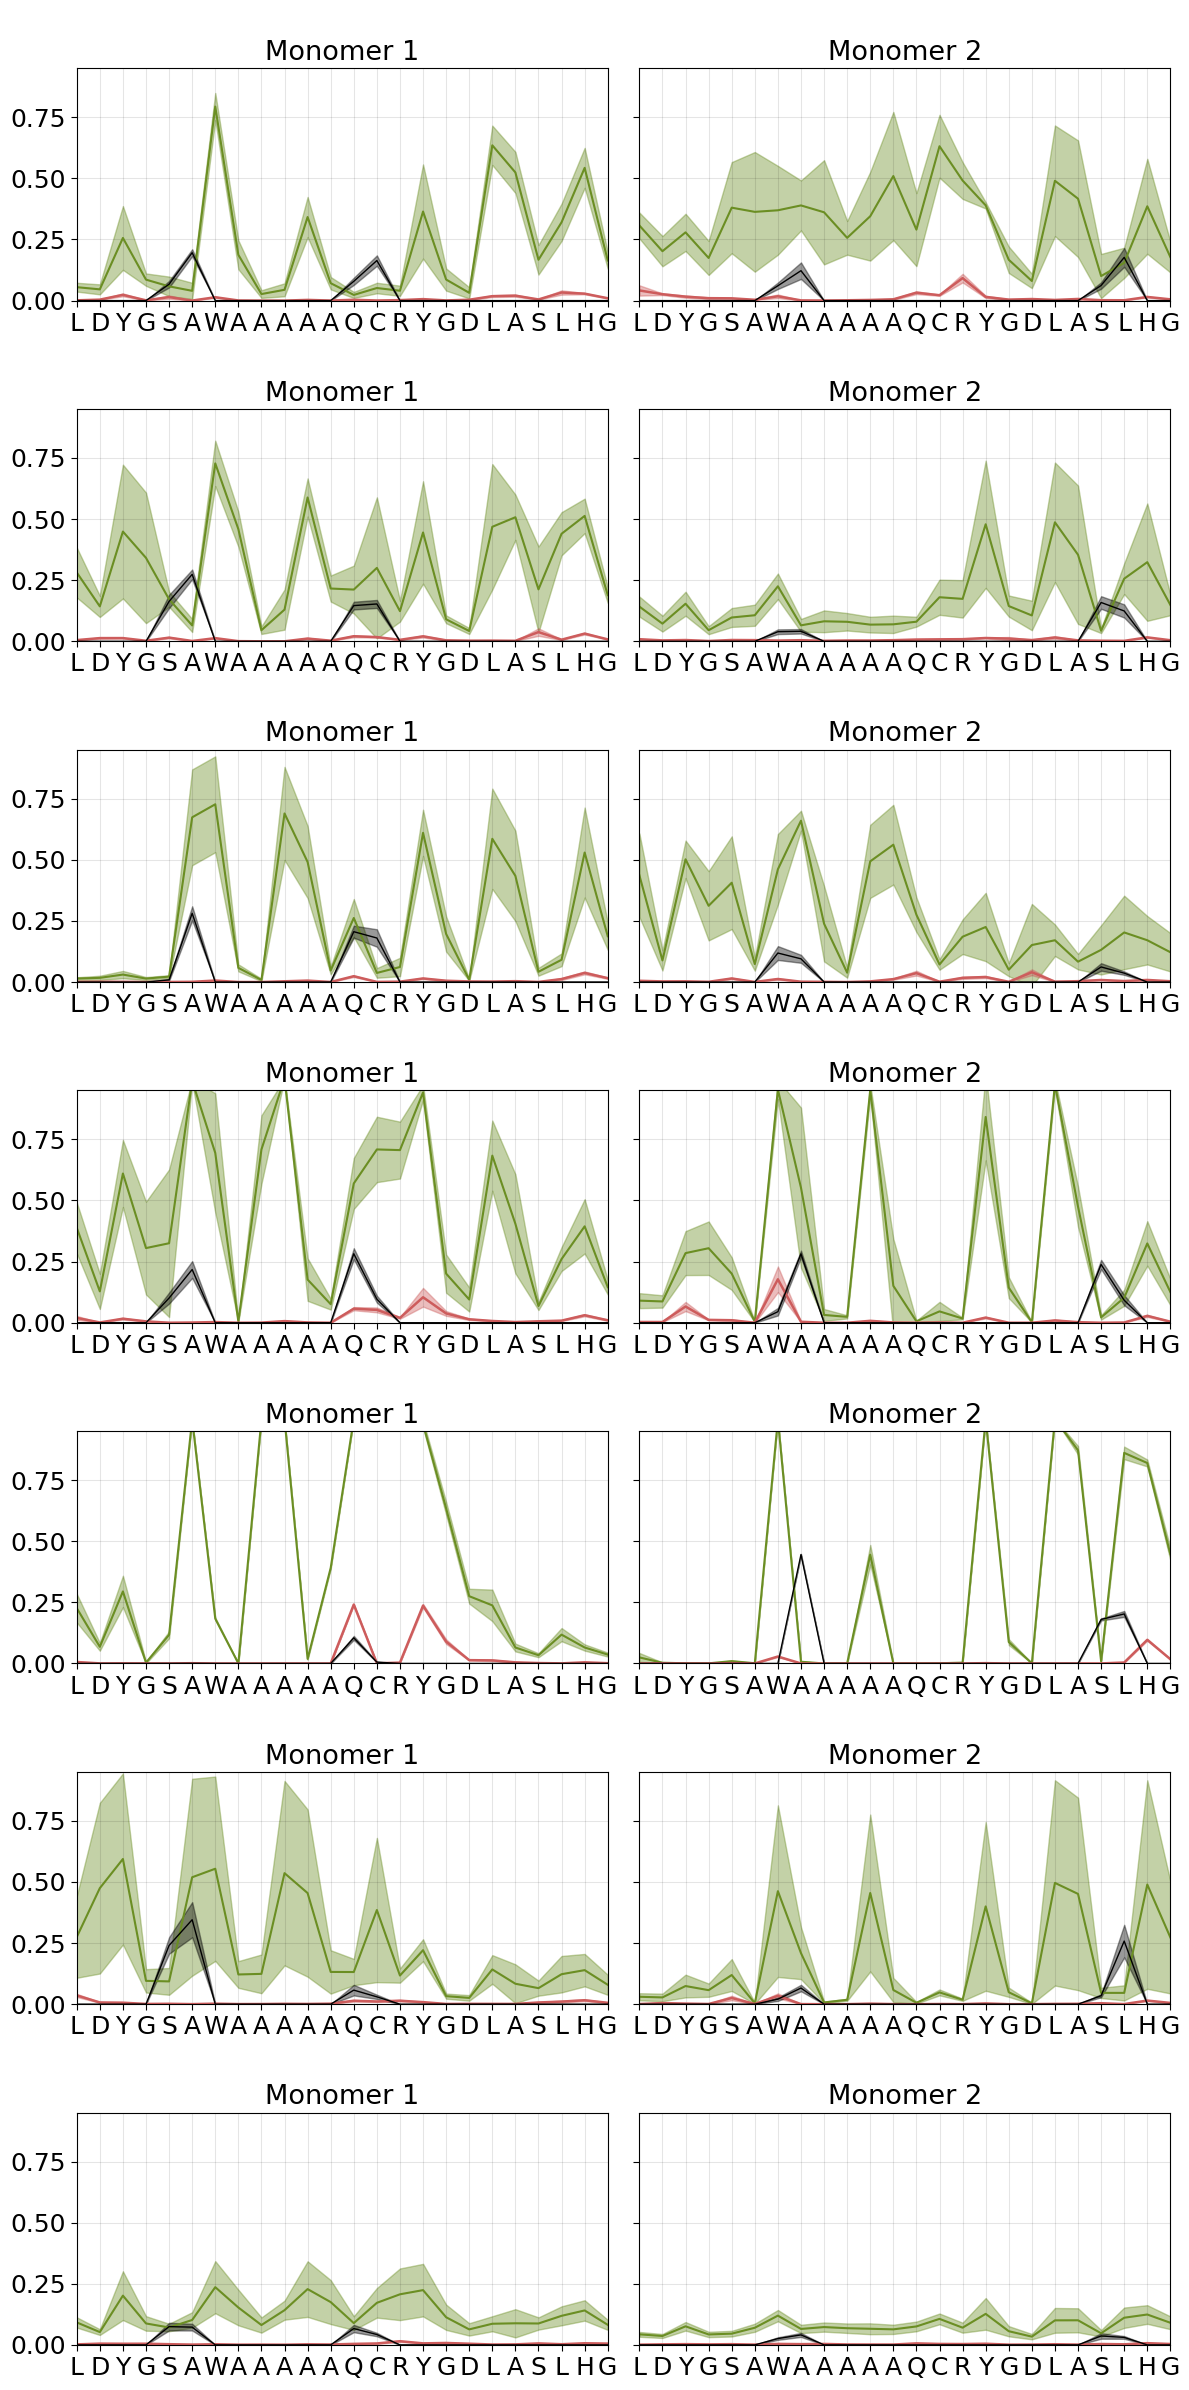

In [482]:
fig, axes = plt.subplots(7, 2, figsize=(12, 24), sharex=False, sharey=True)
font_scale=1.5
for i, (ax, frames) in enumerate(zip(axes, frames_cl)):
    
    mu, error = block_error(hphob_contacts[frames],
                          #confidence_level=.95,
                          lower_upper=True)
    mu, error = np.array_split(mu, 2,), [np.array_split(i, 2) for i in error]
    #mu, err = monomer_aggr_stats(hphob_contacts[frames], lower_upper=True, error=bootstrap)
    lineplot1D(mu[0],
               color='olivedrab',
               fill_color='olivedrab', fill_alpha=.4,
               label='Hydrophobic Contacts',
               ax=ax[0], y1=error[0][0],
               y2=error[1][0], legend=False, title='\nMonomer 1',
               font_scale=font_scale)
    
    lineplot1D(mu[1],
               color='olivedrab', fill_color='olivedrab', fill_alpha=.4,
               label='Hydrophobic Contacts', ax=ax[1], y1=error[0][1],
               y2=error[1][1], legend=False,title='\nMonomer 2',
               font_scale=font_scale)
    
    
    mu, error = block_error(hbonds[frames],
                          #confidence_level=.95,
                          lower_upper=True)
    mu, error = np.array_split(mu, 2,), [np.array_split(i, 2) for i in error]
    lineplot1D(mu[0],
             color='indianred',
             fill_color='indianred',
             fill_alpha=.4,
             label='H-Bonds',
             ax=ax[0],
             alpha=1,
             lw=1.8,
             y1=error[0][0],
             y2=error[1][0],
             legend=False,title='\nMonomer 1', 
             font_scale=font_scale
            )
    #ax.axvline(x=23.5, color='k', linestyle='-', linewidth=2)

    lineplot1D(mu[1],
             color='indianred',
             fill_color='indianred',
             fill_alpha=.4,
             label='H-Bonds',
             ax=ax[1],
             alpha=1,
             lw=1.8,
             y1=error[0][1],
             y2=error[1][1],
             legend=False, title='\nMonomer 2',
             font_scale=font_scale
            )

    mu, error = block_error(stacking[frames],
                            #confidence_level=.95,
                            lower_upper=True)
    mu, error = fill_1d(np.zeros(48), mu, np.repeat(aro_bool, 2)), [fill_1d(np.zeros(48), i, np.repeat(aro_bool, 2)) for i in error]
    mu, error = np.array_split(mu, 2,), [np.array_split(i, 2) for i in error]
    
    lineplot1D(mu[0],
             color='black',
             fill_color='black',
             y1=error[0][0],
             y2=error[1][0],
             fill_alpha=.4,
             ls='-',
             lw=1,
             label='Aromatic Stacking',
             ax=ax[0],
             label_stride=1,
             #top_xticks=['', 395, 400, 405, 410, ''],
             xticks=codes,
             xticks_rotation=0,
             title='\nMonomer 1',
             #title=f'State {i+1}',
             legend=False,
             font_scale = font_scale,
             
             #xlabel='Monomer 1                       Monomer 2'
             
            )
    lineplot1D(mu[1],
             color='black',
             fill_color='black',
             y1=error[0][1],
             y2=error[1][1],
             fill_alpha=.4,
             ls='-',
             lw=1,
             label='Aromatic Stacking',
             ax=ax[1],
             #top_xticks=['', 395, 400, 405, 410, ''],
             xticks=codes[:24],
             xticks_rotation=0,
             title='\nMonomer 2',
             #title=f'State {i+1}',
             legend=False,
             font_scale = font_scale
            )
    
    #if i == 0:
        #ax[1].legend(bbox_to_anchor=[1, 1])
    ax[0].set_ylim(0, .95)
    #ax.grid(which='major', visible=True, axis='y')
    ax[0].grid(which='major', color='black', linestyle='-', linewidth=0.8, axis='both', alpha=.1)
    #ax[0].tick_params(axis='x', labelsize=10)
    
    ax[1].set_ylim(0, .95)
    #ax.grid(which='major', visible=True, axis='y')
    ax[1].grid(which='major', color='black', linestyle='-', linewidth=0.8, axis='both', alpha=.1)
    #ax[1].tick_params(axis='x', labelsize=10)

fig.tight_layout()


fig.savefig(f'{paths[2]}/ligand_interactions_clusters.png', dpi=1000, bbox_inches='tight')
#fig.legend(bbox_to_anchor=[1.3, .9])

 # Visualize latent space

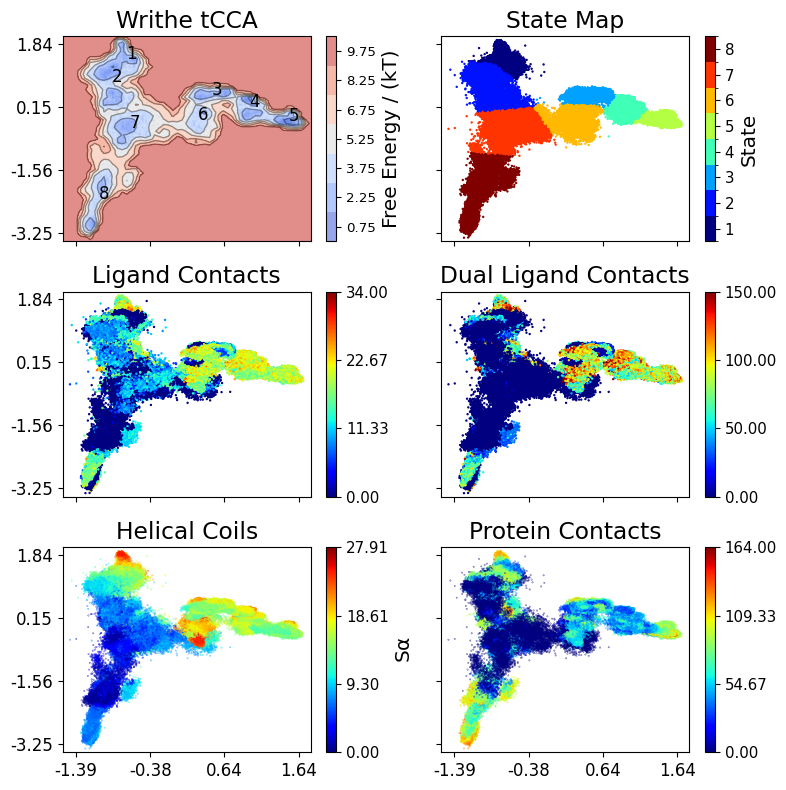

In [496]:
fig, ax = plt.subplots(3, 2, figsize=(8, 8), sharey=True, sharex=True)
ax=ax.flat
fes2d(proj, cluster_centers=centroids, ax=ax[0],
      **fes2d_args, title='Writhe tCCA', font_scale=1.2)

proj2d(proj, 
       ax=ax[1],
       c=macrostates,
       state_map=True,
       cmap='jet',
       title = 'State Map',
       font_scale=1.2)

proj2d(proj, 
       ax=ax[2],
       c=ligand_distances.contacts(0.6).sum(-1),
       cmap='jet',
       title = 'Ligand Contacts',
       font_scale=1.2)

proj2d(proj, 
       ax=ax[3],
       c=np.multiply.reduce([i.sum(-1) for i in split(ligand_distances.contacts(0.6))]),
       cmap='jet',
       title = 'Dual Ligand Contacts',
       font_scale=1.2,
       vmax=150)

proj2d(proj,  ax=ax[4], c=sa.sum((0,2)),
       cmap='jet', title = 'Helical Coils',
       font_scale=1.2,dot_size=.05,
       vmin=0, cbar_label=r'S$\alpha$')

proj2d(proj, 
       ax=ax[5],
       c=ca_distances.contacts(1).sum(-1),
       cmap='jet',
       title = 'Protein Contacts',
       font_scale=1.2,
       vmin=0,
       dot_size=.05)

fig.tight_layout()
fig.savefig(f'{paths[-1]}/projections.png', dpi=1000, bbox_inches='tight')

 # protein contacts (CA-CA distance < 1 nm) and helical propensities (DSSP algorithm)

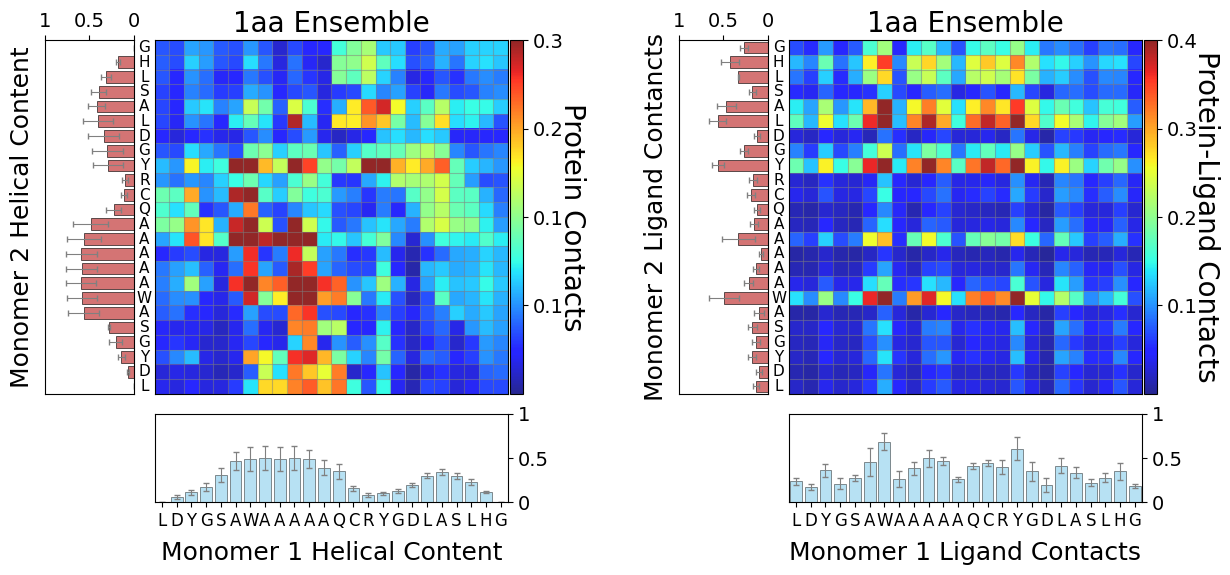

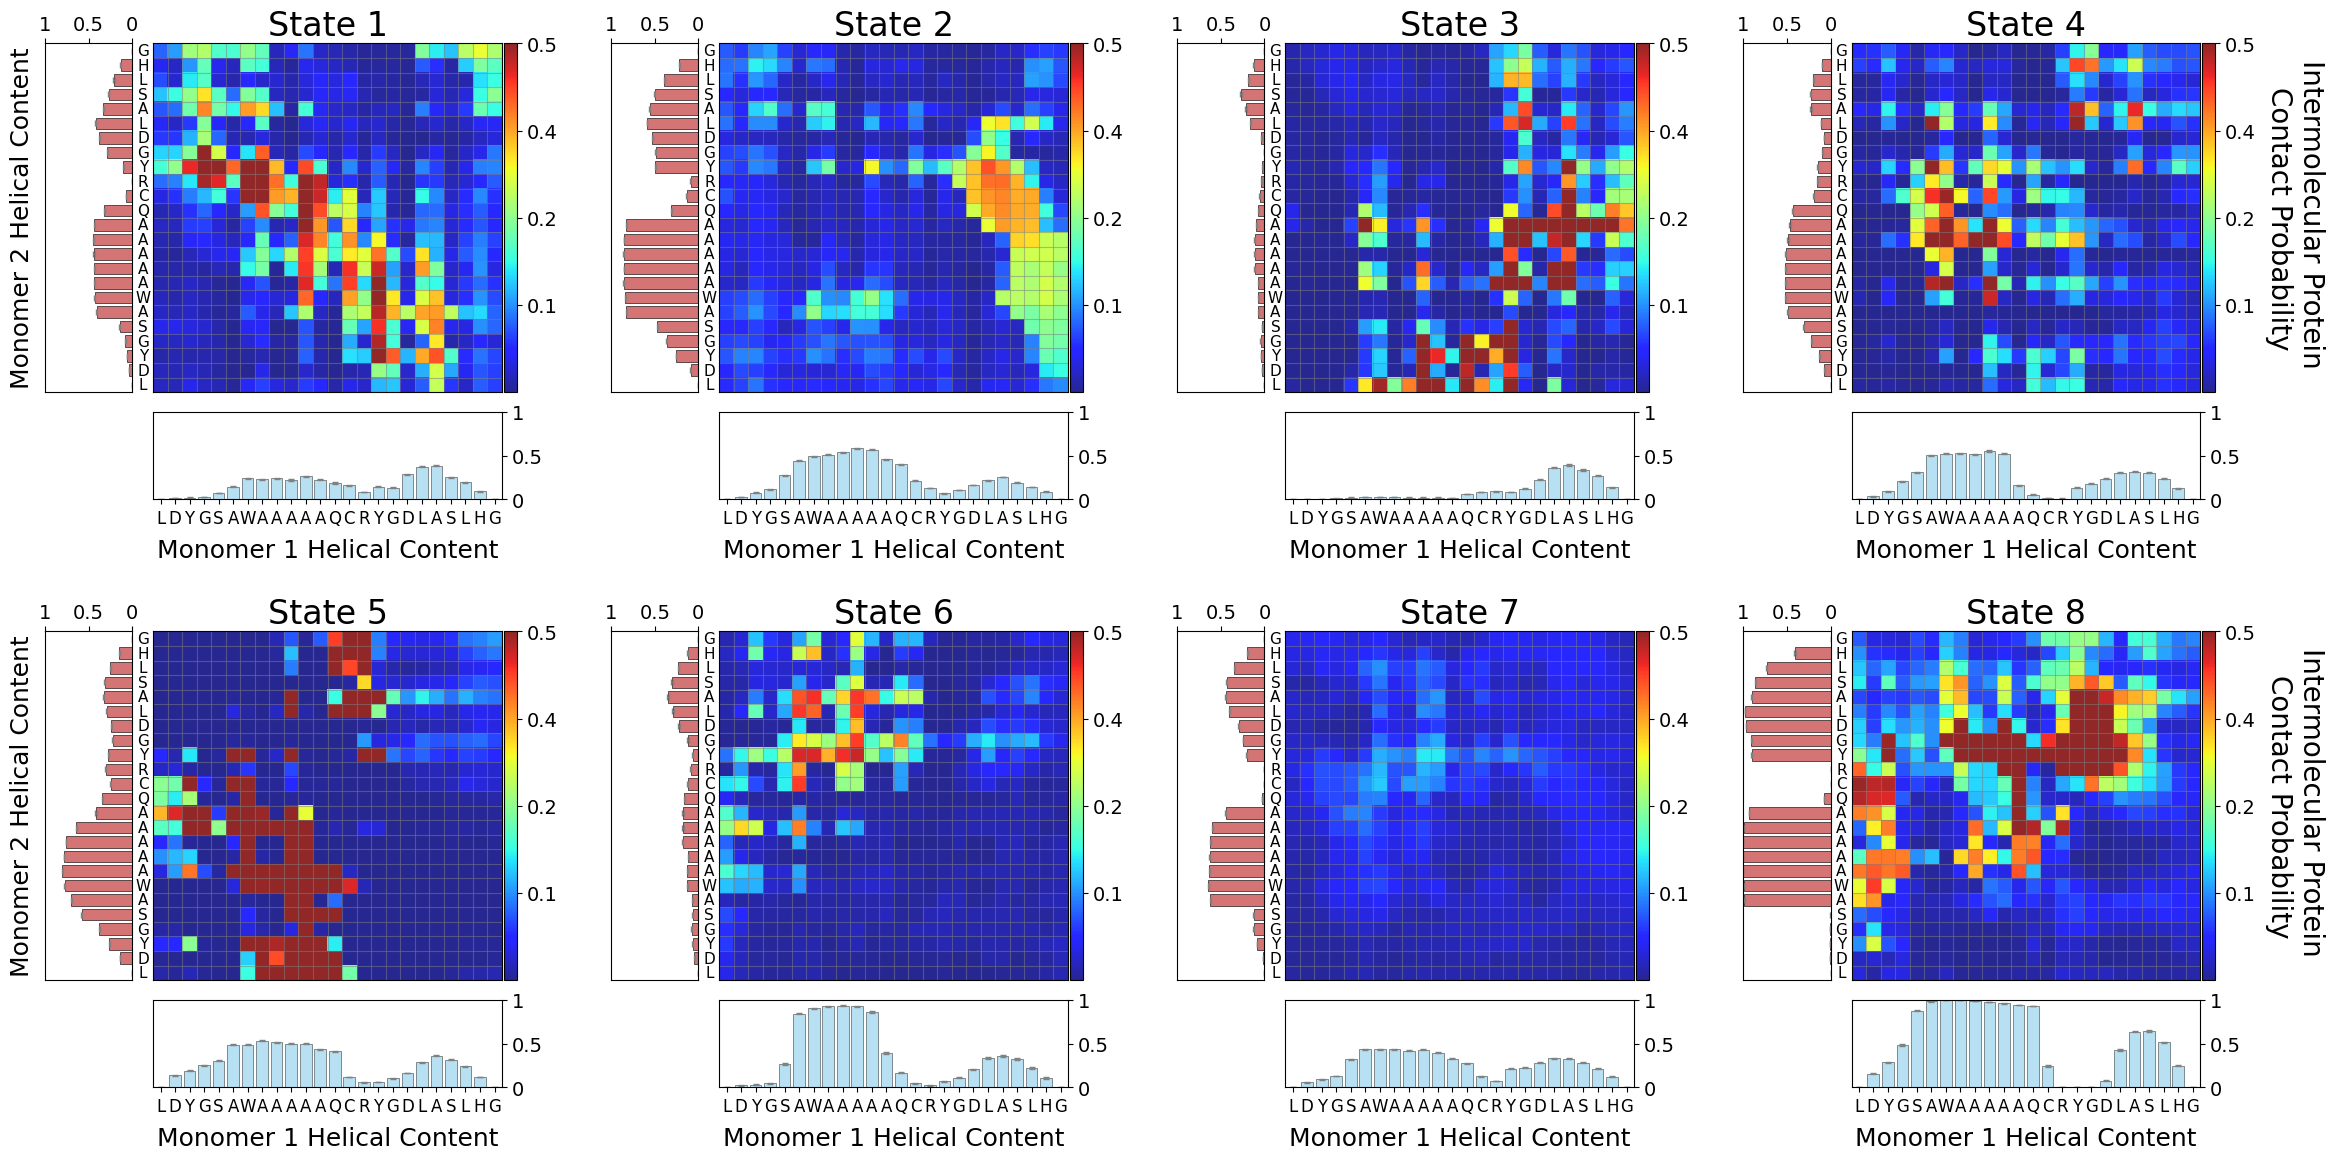

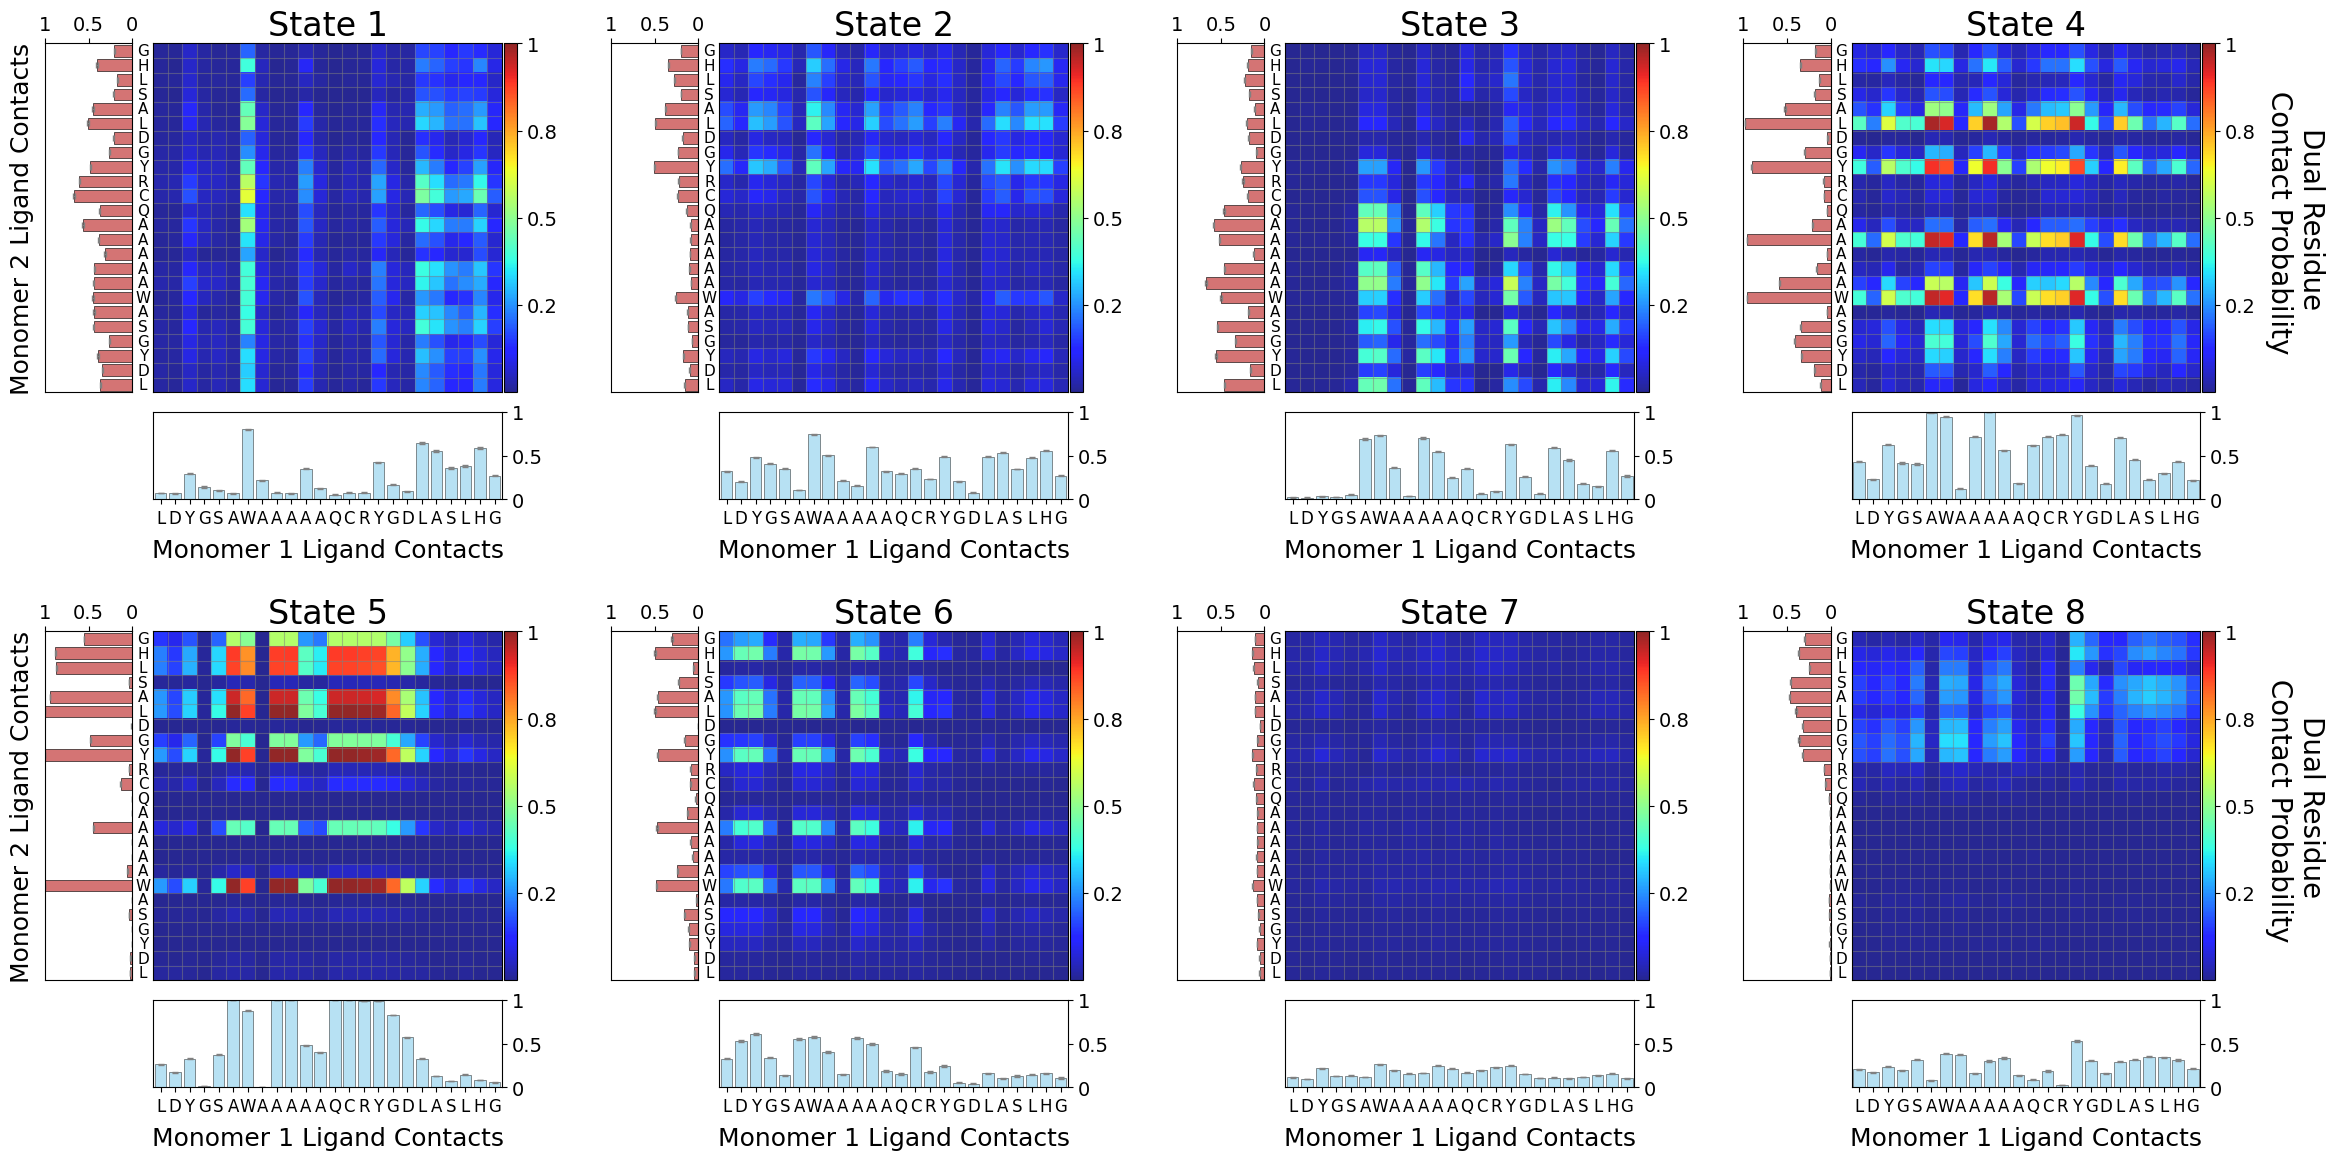

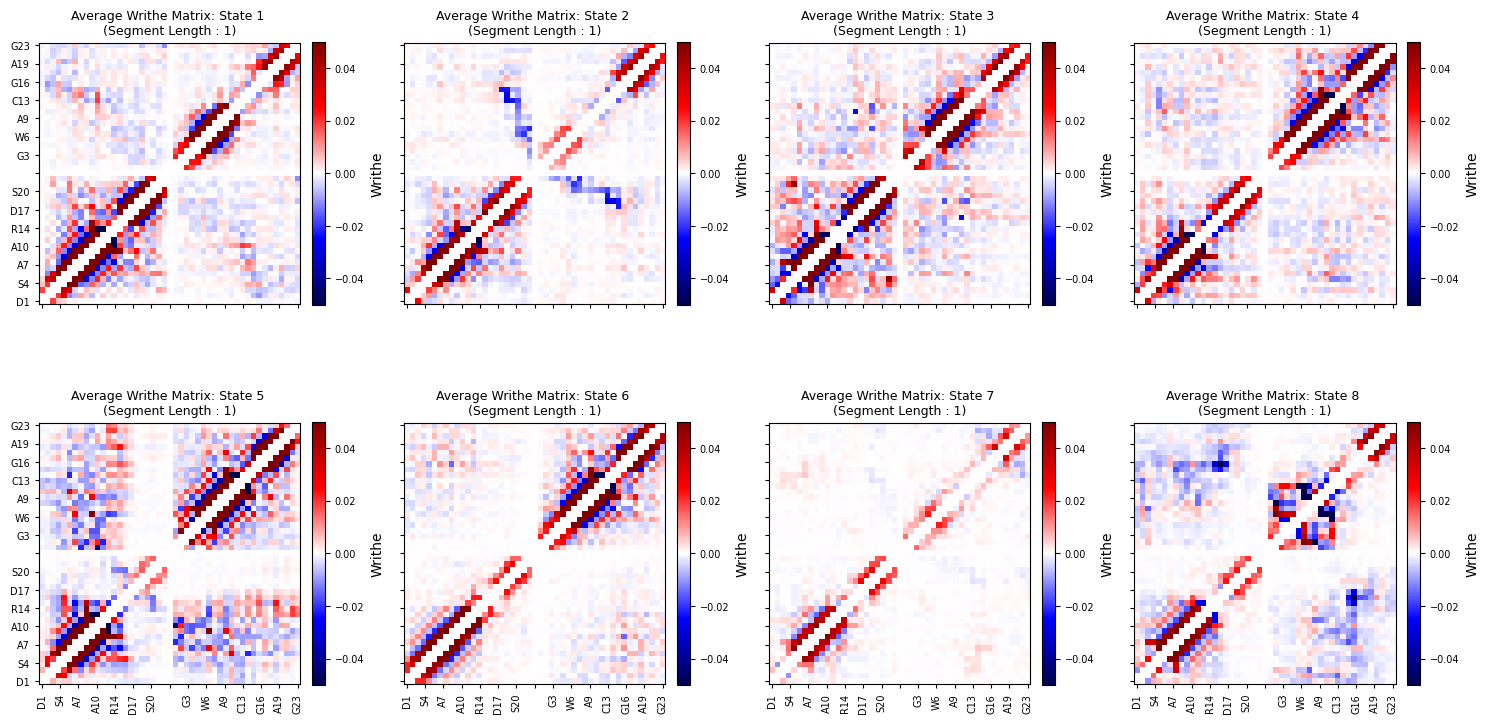

In [14]:

# import writhe_tools
# reload(writhe_tools)
# reload(writhe_tools.plots)


fig, ax = plt.subplots(1, 2, figsize=(15, 6))
dssp_error = split(block_error(dssp.transpose(1, 0, 2).reshape(-1, 48))[1])
build_matrix_boxplot_grid(ca_distances.matrix(contacts=True, cut_off=1).mean(0).T,
                          dssp[0].mean(0),
                          dssp[1].mean(0),
                          bottom_errors=dssp_error[0],
                          left_errors=dssp_error[1],
                          cmap='jet',
                          title=f'{label} Ensemble',
                          bottom_title='Monomer 1 Helical Content',
                          vmin=0,
                          vmax=.3,
                          marginal_max=1,
                          left_title='Monomer 2 Helical Content',
                          cbar_label='Protein Contacts',
                          ticks=codes,
                          ecolor='gray',
                          ax=ax[0],
                          flip_y=True
                          
                          #path=f'{paths[2]}/protein_protein_helix_ensemble.png'
                         )



error = split(block_error(ligand_distances.contacts(.6))[1])
i, j = split(ligand_distances.contacts(.6))
build_matrix_boxplot_grid((i.T @ j).T / len(i),
                          i.mean(0),
                          j.mean(0),
                          bottom_errors=error[0],
                          left_errors=error[1],
                          cmap='jet',
                          title=f'{label} Ensemble',
                          bottom_title='Monomer 1 Ligand Contacts',
                          vmin=0,
                          vmax=.4,
                          marginal_max=1,
                          left_title='Monomer 2 Ligand Contancts',
                          cbar_label='Protein-Ligand Contacts',
                          ticks=codes,
                          ecolor='gray',
                          ax=ax[1],
                          flip_y=True
                          #path=f'{paths[2]}/ligand_contacts_ensemble.png'
                         )

fig, axes = plt.subplots(2, 4, figsize=(28, 14), sharey=True, sharex=True)
for i, (ax, frames) in enumerate(zip(axes.flat, group_by(macrostates))):
    dssp_error = split(bootstrap(dssp.transpose(1, 0, 2).reshape(-1, 48)[frames], 0.999)[1])

    build_matrix_boxplot_grid(ca_distances.matrix(contacts=True, cut_off=1, index=frames).mean(0).T,
                          dssp[0][frames].mean(0),
                          dssp[1][frames].mean(0),
                          title_size=24,
                          bottom_errors=dssp_error[0],
                          left_errors=dssp_error[1],
                          cmap='jet',
                          title=f'State {i+1}', #f'{label} : State {i+1}',
                          bottom_title='Monomer 1 Helical Content',
                          vmin=0,
                          vmax=.5,
                          marginal_max=1,
                          left_title='Monomer 2 Helical Content' if (i == 0 or i == 4) else '',
                          cbar_label='Intermolecular Protein \nContact Probability' if (i == 3 or i == 7) else '' ,
                          ticks=codes,
                          ax=ax,
                          font_scale=1,
                          cbar_labelpad = 50,
                          flip_y = True,
                          #path=f'{paths[0]}/protein_protein_helix_state_{i+1}.png',
                             )
#fig.tight_layout()
fig, axes = plt.subplots(2, 4, figsize=(28, 14), sharey=True, sharex=True)

for k, (ax, frames) in enumerate(zip(axes.flat, group_by(macrostates))):
    i, j = split(ligand_distances.contacts(.6)[frames])
    i_err, j_err = split(bootstrap(ligand_distances.contacts(.6)[frames], 0.999)[1])
                       
    build_matrix_boxplot_grid(matrix=(i.T @ j).T / len(frames),
                              bottom_values=i.mean(0),
                              left_values=j.mean(0),
                              title_size=24,
                              bottom_errors=i_err,
                              left_errors=j_err,
                              cmap='jet',
                              title=f'State {k+1}',
                              bottom_title='Monomer 1 Ligand Contacts', vmin=0, vmax=1,
                              left_title='Monomer 2 Ligand Contacts' if (k == 0 or k == 4) else '',
                              cbar_label='Dual Residue\n Contact Probability' if (k == 3 or k == 7) else '' ,
                              cbar_labelpad = 50,
                              ax=ax,
                              font_scale=1,
                              ticks=codes,
                              flip_y=True

                              #path=f'{paths[1]}/ligand_contacts_state_{k+1}.png',
                             )


writhe.compute_writhe(1,
                      cuda=True,
                      store_results=True,
                      lengths=unitcell_lengths)
writhe.writhe_features[:, (writhe.segments[:, :2] == np.array([23, 24])).all(1) | (writhe.segments[:, 2:] == np.array([23, 24])).all(1)
                          ] = 0

fig, axes = plt.subplots(2, 4, figsize=(15, 8), sharex=True, sharey=True)
for i, (ax, frames) in enumerate(zip(axes.flat, group_by(macrostates))):
    writhe.plot_writhe_matrix(frames,
                              ax=ax, 
                              dscr=f'State {i+1}',
                              vmax=0.05,
                              laplacian=False,
                              yticks=np.tile(np.array([f'{j}{i + 1}' for i, j in enumerate(codes[1:])] + ['']), 2),
                              xticks=np.tile(np.array([f'{j}{i + 1}' for i, j in enumerate(codes[1:])] + ['']), 2),
                              label_stride=3, xticks_rotation=90
                             )
fig.tight_layout()

# fes2d(proj[:, :2], cluster_centers=group_by(cg.astype(int), proj[:, :2], partial(np.mean, axis=0)),
#      bins=30)
    

In [17]:
dtraj_files = lsdir('/data/r1r2', 'micro')
dict(zip(dtraj_files, [np.unique(np.load(i)).size for i in dtraj_files]))

{'/data/r1r2/best_micro_dtraj_1aa.npy': 200,
 '/data/r1r2/best_micro_dtraj_apo.npy': 250,
 '/data/r1r2/best_micro_dtraj_epi.npy': 400}

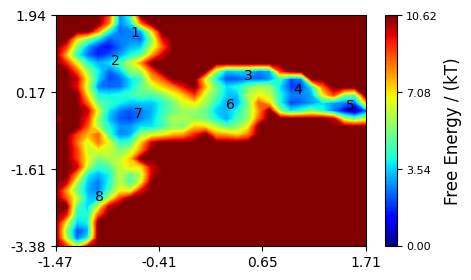

In [11]:
fes2d(proj[:, :2], cluster_centers=group_by(cg.astype(int), proj[:, :2], partial(np.mean, axis=0)),
     bins=30, mask=False)

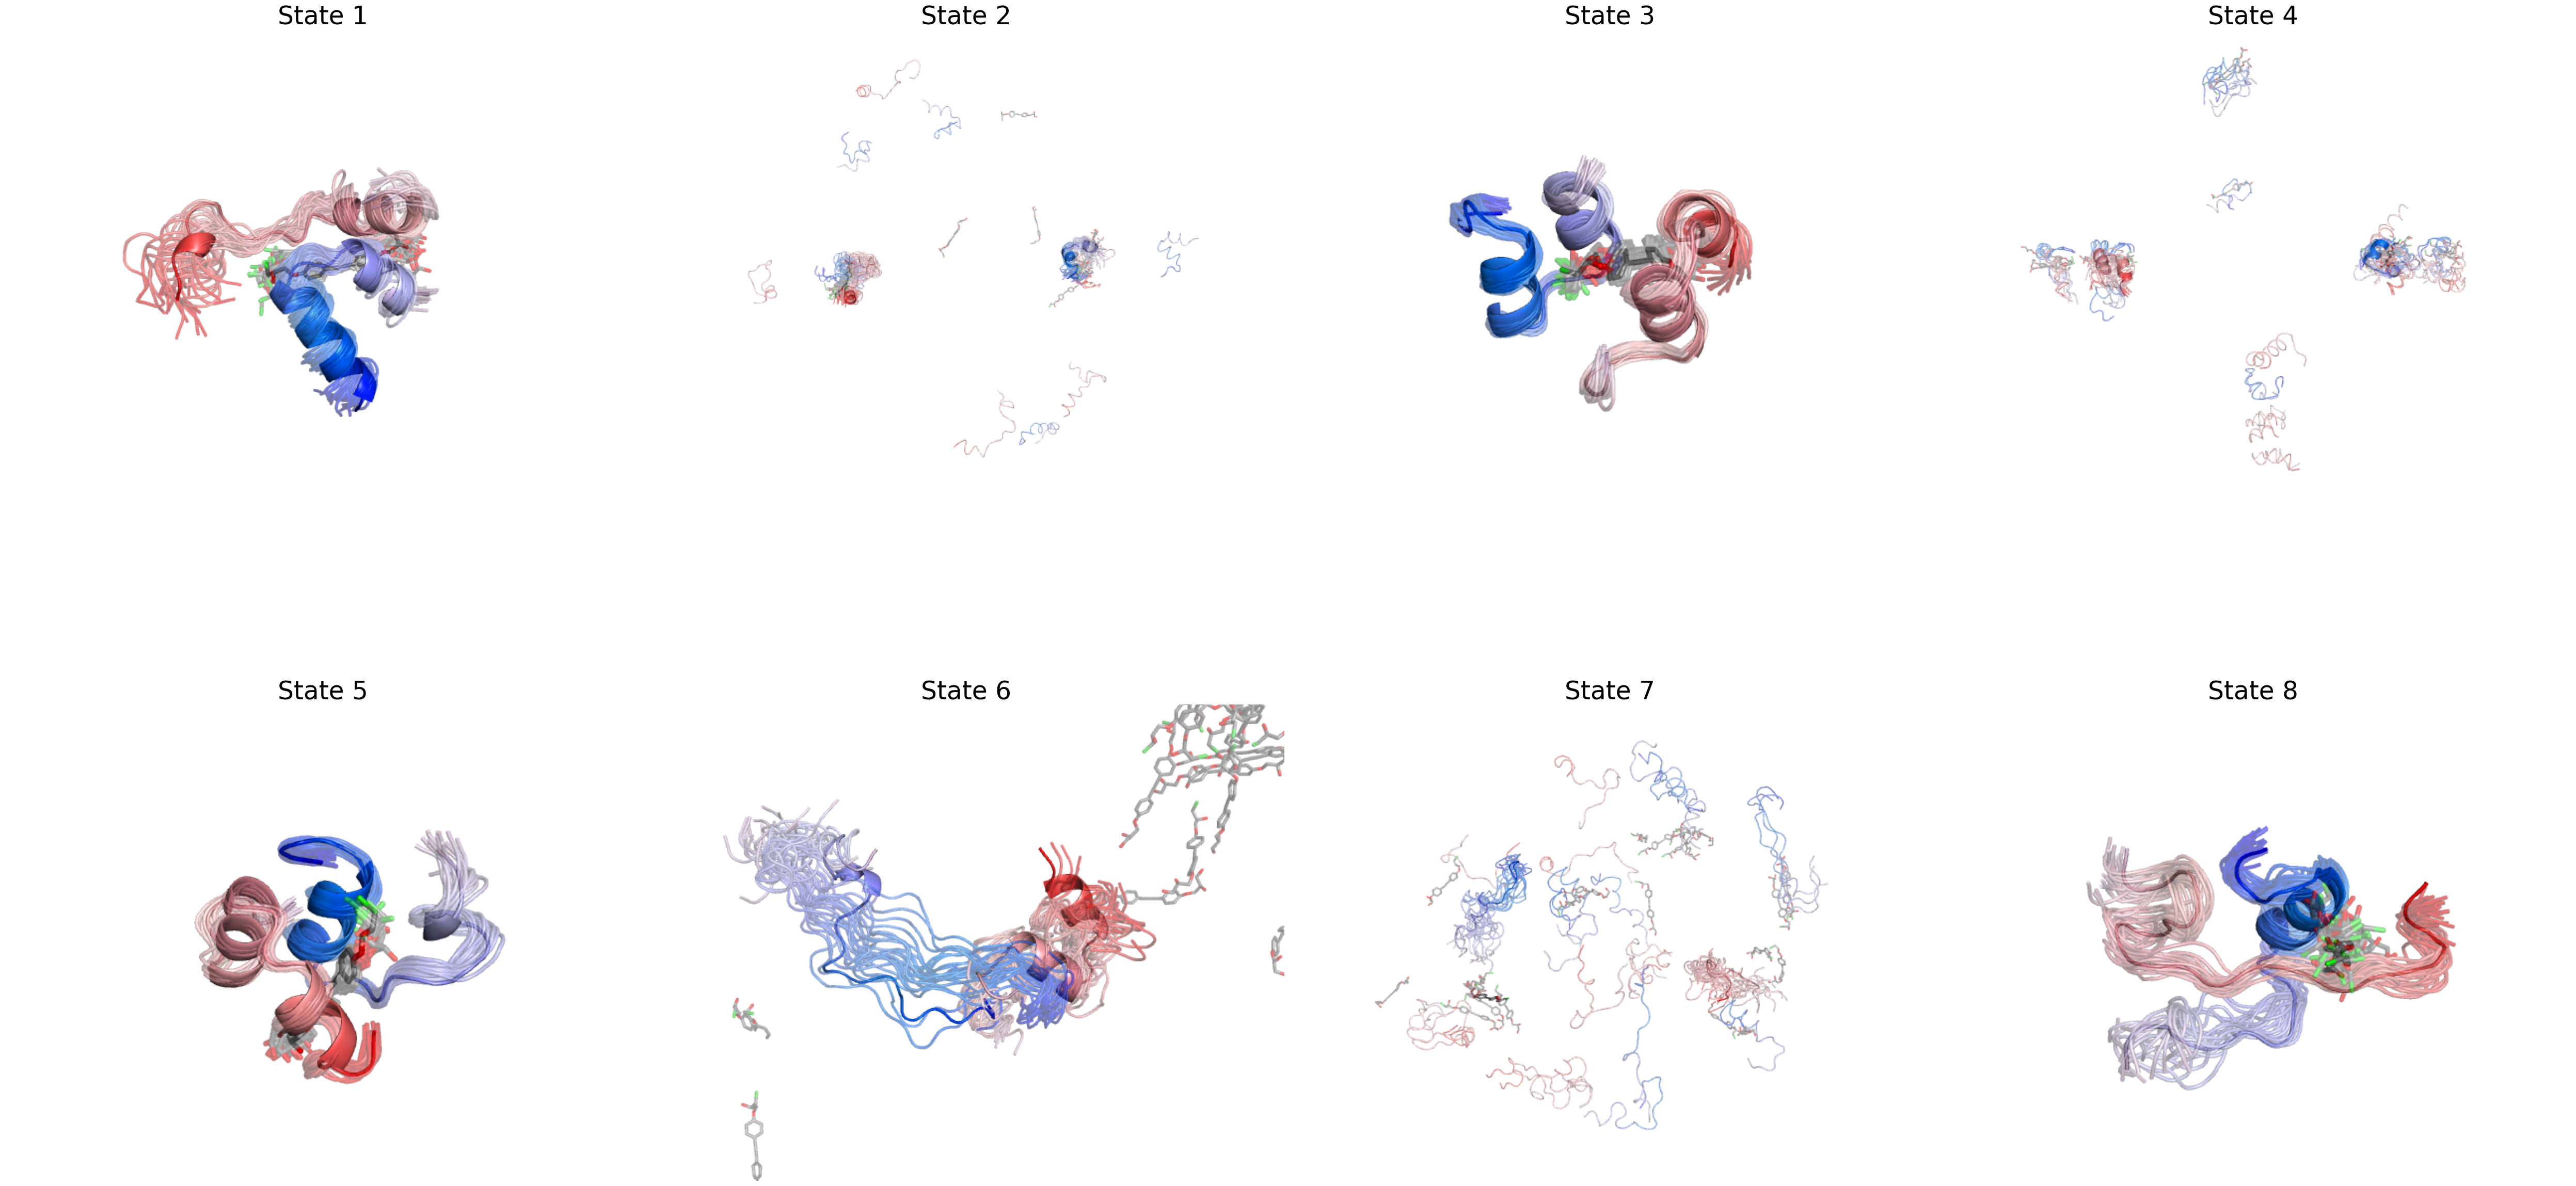

In [24]:
from writhe_tools.md_tools import rmsd_sort
from visualize import visualize_clustering
#features = np.concatenate([dssp.transpose(1, 0, 2).reshape(-1, 48), ca_distances.contacts(1)], 1)

features =  writhe_features #np.concatenate([writhe_features, 5 * sa.transpose(1, 0, 2).reshape(-1, 38)], 1) # writhe_features # proj[:, :2]
features = proj[:, :2]
mus = group_by(macrostates, features, partial(np.mean, axis=0))
writhe_centroids = []
for frames, center in zip(group_by(macrostates), mus):
    writhe_centroids.append(frames[np.linalg.norm(features[frames] - center, axis=-1).argsort()])

# traj = md.load(ligand_files[0],
#                #top=ligand_pdbs[0],
#                top = '/data/fixed_for_pymol.pdb'
#               ).center_coordinates()
traj = md.load(ligand_files[1], top=ligand_pdbs[1])#.center_coordinates()

fig, axes = plt.subplots(2, 4, figsize=(50, 30))
for i, (frames, ax) in enumerate(zip(writhe_centroids, axes.flat)):
    indices = rmsd_sort(frames, traj, 0)
    visualize_clustering(traj,
                         indices,
                         path='./',
                         name = f"State {i+1}",
                         n_frames=25, 
                         draw_style='cartoon',
                         ensemble_draw_style='loop',
                         transparency=.45,
                         ax=ax)
    ax.set_title(f"State {i+1}", size=35)
fig.tight_layout()

del traj

Text(0.7, 83, '51.5 ns')

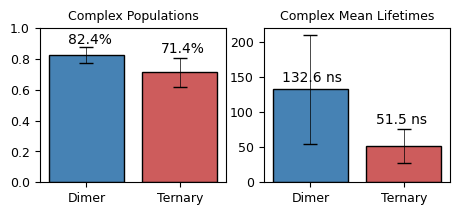

In [13]:

_, ax = plt.subplots(1, 2,
                     figsize=(5.3, 2), 
                     #dpi=500,
                    )
mu, err = block_error(np.stack([dimer, ternary], 1))


box_plot(mu,
         errors=err,
         labels='Dimer,Ternary'.split(','),
         error_capsize=5,
         error_linewidth=.5,
         error_capthick=1,
         error_color='black',
         #cmap="coolwarm",
         color_list=['steelblue', 'indianred'],
         alpha=1, 
         font_scale=state_font_scale, 
         title = 'Complex Populations',
         rotation=0,
         trunc=trunc,
         pre_trunc=pre_trunc,
         ymin=0,
         ymax=1,
         width=0.8,
         ax=ax[0])

ax[0].text(-.2, .9, f'{100 * mu[0] :.1f}%')
ax[0].text(.8, .84, f'{100 * mu[1] :.1f}%')


mu = np.array([i.mean() for i in [dimer_lengths, ternary_lengths]])
err = np.array([bootstrap(i)[-1] for i in [dimer_lengths, ternary_lengths]])

box_plot(mu,
         errors=err,
         labels='Dimer,Ternary'.split(','),
         error_capsize=5,
         error_linewidth=.5,
         error_capthick=1,
         error_color='black',
         #cmap="coolwarm",
         color_list=['steelblue', 'indianred'],
         alpha=1, 
         font_scale=state_font_scale, 
         title = 'Complex Mean Lifetimes',
         rotation=0,
         trunc=trunc,
         pre_trunc=pre_trunc,
         ymin=0,
         ymax=220,
         #ylabel='Time (ns)',

         width=0.8,
         ax=ax[1])

ax[1].text(-.31, 143, f'{mu[0] :.1f} ns')
ax[1].text(.7, 83, f'{mu[1] :.1f} ns')

In [ ]:
from writhe_tools.writhe_numba import pbc_correct
from writhe_tools.stats import cross_correlation, plot_cross_correlation
extent = ((0, 400), (0, 30))
fes2d(
      np.exp(-.25 * ca_distances.distances**2).sum(-1),
      sa.sum((0,-1)),
      ylabel=r'S$\alpha$'+" Total",
      xlabel="Protein Contacts",
      bins=40,
      tick_decimals=0,
      title=label,
      mask=False,
      contour_lines=False,
      alpha_contours=.7,
      alpha_lines=.1,
      mask_thresh=5,
      n_contours=30,
      extent=extent, figsize=(3, 2.5)
)
plt.savefig(f'./{label}_helix_contact_fes', dpi = 1000, bbox_inches = 'tight')

In [ ]:
from writhe_tools.writhe_numba import pbc_correct
from writhe_tools.stats import cross_correlation, plot_cross_correlation

lags, corr = cross_correlation(sa.sum((0,-1)),
                                       #ca_distances.contacts(1).mean(-1),
                                       np.exp(-.25 * ca_distances.distances**2).mean(-1),
                                     )
ax=plt.subplots(1, 1,figsize=(4, 2.5))[-1]
plot_cross_correlation(lags, corr, 10000, normalize=False, ax=ax)
ax.set_title(r'S$\alpha$(t) * Protein Contacts(t + $\tau$)')

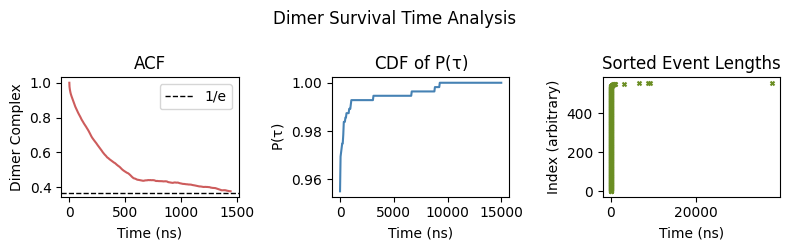

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(8, 2.5))

ac = acf(dimer)
#get the correlation time
#tau.append(get_tau(ac))
axes[0].plot(np.arange(0, 6000) * 0.24,  # scale the time
             ac[:6000],
             c="indianred",
            )
bins=300
axes[1].plot( np.linspace(0, 15000, bins), np.cumsum(pmf(dimer_lengths, bins=bins, range=(0, 15000))[0]), c='steelblue')
axes[2].scatter(dimer_lengths[::-1], np.arange(len(dimer_lengths)), c='olivedrab', s=8, marker='x')



axes[2].set_xlabel('Time (ns)')
axes[2].set_ylabel('Index (arbitrary)')
axes[2].set_title('Sorted Event Lengths')


axes[1].set_ylabel(r'P($\tau$)')
axes[1].set_xlabel('Time (ns)')
#axes[1].legend()
axes[1].set_title('CDF of ' + r'P($\tau$)')

axes[0].axhline(y=1/np.exp(1),
                linestyle='--',
                color='black',
                linewidth=1,
                label='1/e',
               )

axes[0].set_xlabel(r"Time (ns)")
axes[0].set_ylabel("Dimer Complex")
axes[0].legend(ncol=2)
axes[0].set_title('ACF')

#axes[2].legend()
fig.suptitle('Dimer Survival Time Analysis')
fig.tight_layout()

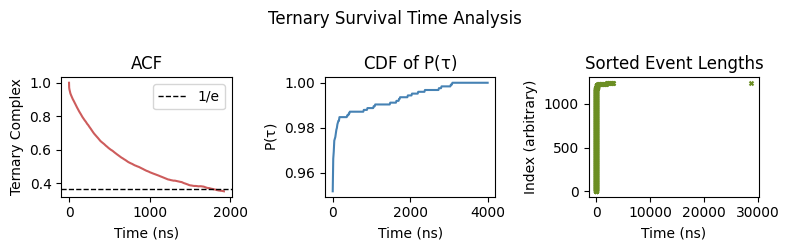

In [9]:

fig, axes = plt.subplots(1, 3, figsize=(8, 2.5))


ac = acf(ternary)
#get the correlation time
#tau.append(get_tau(ac))
axes[0].plot(np.arange(0, 8000) * 0.24,  # scale the time
             ac[:8000],
             c="indianred",
            )
bins=300
axes[1].plot( np.linspace(0, 4000, bins), np.cumsum(pmf(ternary_lengths, bins=bins, range=(0, 4000))[0]), c='steelblue')
axes[2].scatter(ternary_lengths[::-1], np.arange(len(ternary_lengths)), c='olivedrab', s=8, marker='x')



axes[2].set_xlabel('Time (ns)')
axes[2].set_ylabel('Index (arbitrary)')
axes[2].set_title('Sorted Event Lengths')

axes[1].set_ylabel(r'P($\tau$)')
axes[1].set_xlabel('Time (ns)')
#axes[1].legend()
axes[1].set_title('CDF of ' + r'P($\tau$)')

axes[0].axhline(y=1/np.exp(1),
                linestyle='--',
                color='black',
                linewidth=1,
                label='1/e',
               )

axes[0].set_xlabel(r"Time (ns)")
axes[0].set_ylabel("Ternary Complex")
axes[0].legend(ncol=2)
axes[0].set_title('ACF')

#axes[2].legend()
fig.suptitle('Ternary Survival Time Analysis')
fig.tight_layout()

Text(0.5, 1.0, 'Event Protein Contact distributions')

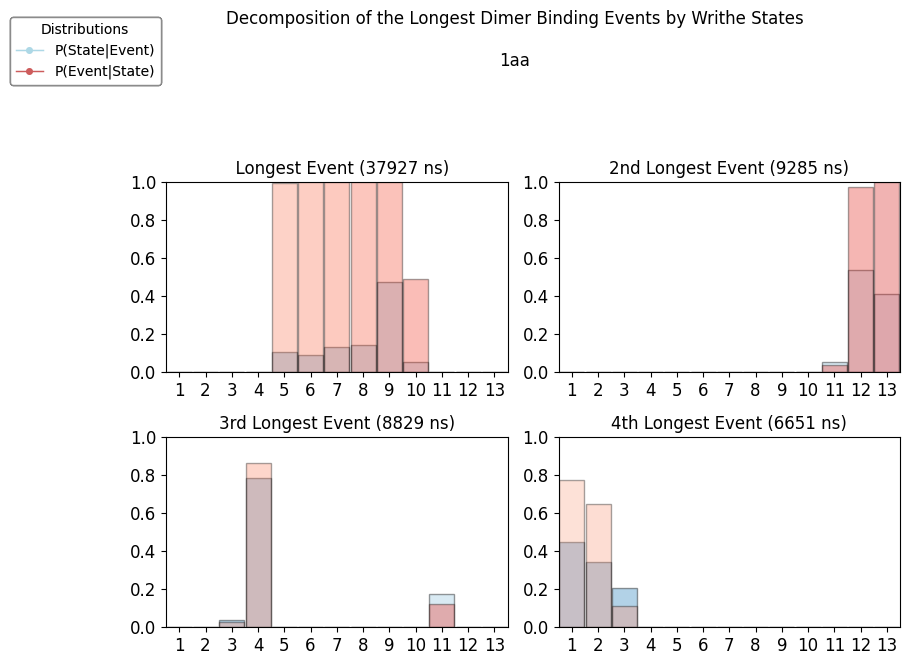

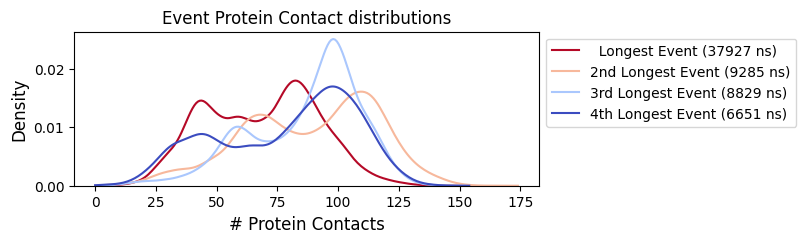

In [141]:
import seaborn as sns
fig, axes = plt.subplots(2,2, figsize=(8, 6))
event_title = dict(zip([0, 1, 2, 3], ' ,2nd,3rd,4th'.split(',')))
for i, (frames, length, ax) in enumerate(zip(dimer_events, dimer_lengths, axes.flat)):

    cSE = pmf(macrostates[frames], np.unique(macrostates).size, norm=False, range=(0, np.unique(macrostates).size,))[0]
    cS =  pmf(macrostates, np.unique(macrostates).size, norm=False, range=(0, np.unique(macrostates).size,))[0]
    pES = cSE / cS
    pSE = cSE / cSE.sum()
    
    box_plot(pSE, label_stride=1, cmap='Blues_r',
             ax=ax, alpha=.4, labels=np.arange(len(pES))+1,
             font_scale=2, trunc=trunc, pre_trunc=pre_trunc)
    
    box_plot(pES, label_stride=1, cmap='Reds',
             ax=ax, alpha=.35, font_scale=2,#ylabel="Contact\n Populaton", 
             labels=np.arange(len(pES))+1,
             rotation=0, trunc=trunc, pre_trunc=pre_trunc, ymin=0, ymax=1,
            title = f'{event_title[i]} Longest Event ({length:.0f} ns)')
    
    legend_elements = [Line2D([0], [0],
                              marker="o", 
                              color=color,
                              label=l,
                              markerfacecolor=color,
                              markersize=4,
                              lw=1)
                       for i, (l, color) in enumerate(zip(["P(State|Event)", "P(Event|State)"],
                                                 ["lightblue", "indianred"]))]
    
    fig.legend(handles=legend_elements,title="Distributions",loc="upper left",
           fontsize=10, title_fontsize=10, edgecolor=(.5,.5,.5), ncol=1,
           bbox_to_anchor = [-.14,1.1])
    
    fig.suptitle(f"Decomposition of the Longest Dimer Binding Events by Writhe States\n\n{label}", y=1.1)

fig.tight_layout()




fig, ax = plt.subplots(1, 1, figsize=(6,2))
for i, (frames, length, color) in enumerate(zip(dimer_events[:4], dimer_lengths, get_color_list(4,'coolwarm_r'))):
    
    sns.kdeplot(ca_distances.contacts(1)[frames].sum(-1),
                label=f'{event_title[i]} Longest Event ({length:.0f} ns)',
                common_grid=True,
                ax=ax,
                clip=(0,180),
                color=color)

ax.legend(ncol=1, bbox_to_anchor=[1,1])
ax.set_xlabel('# Protein Contacts', size=12)
ax.set_ylabel('Density', size=12)
ax.set_title('Event Protein Contact distributions', 
                #size=15,
               )

Text(0.5, 1.0, 'Event Ligand Contact distributions')

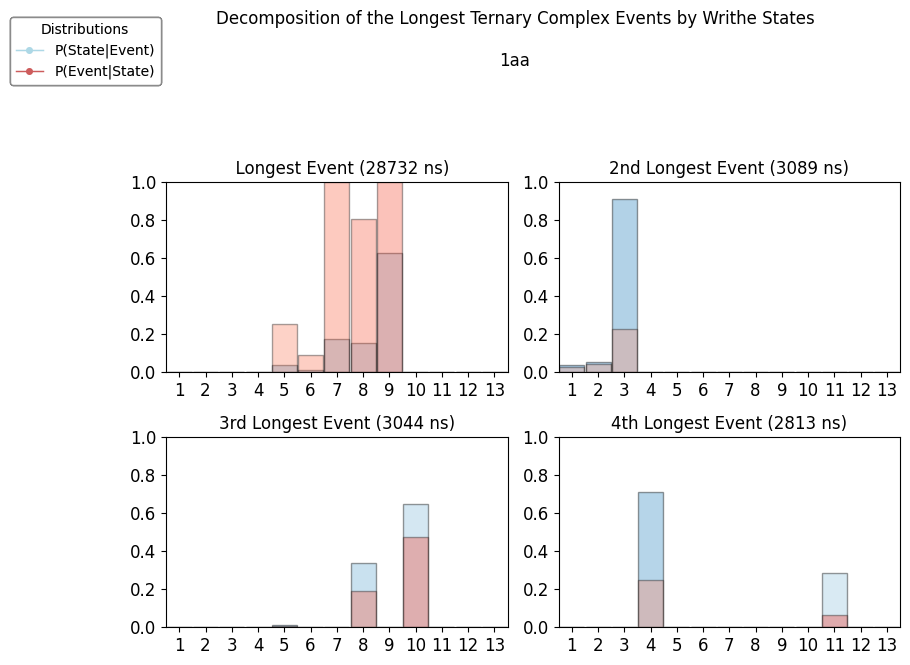

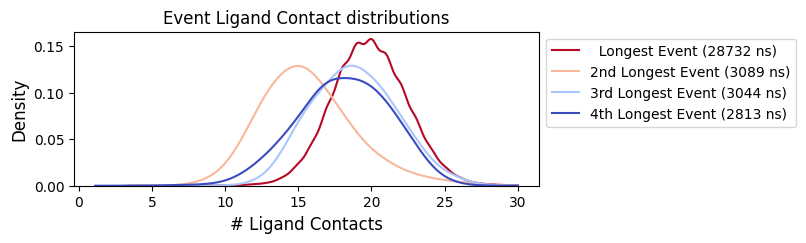

In [142]:
import seaborn as sns
fig, axes = plt.subplots(2,2, figsize=(8, 6))
event_title = dict(zip([0, 1, 2, 3], ' ,2nd,3rd,4th'.split(',')))
for i, (frames, length, ax) in enumerate(zip(ternary_events, ternary_lengths, axes.flat)):

    cSE = pmf(macrostates[frames], np.unique(macrostates).size, norm=False, range=(0, np.unique(macrostates).size,))[0]
    cS =  pmf(macrostates, np.unique(macrostates).size, norm=False, range=(0, np.unique(macrostates).size,))[0]
    pES = cSE / cS
    pSE = cSE / cSE.sum()
    
    box_plot(pSE, label_stride=1, cmap='Blues_r',
             ax=ax, alpha=.4, labels=np.arange(len(pES))+1,
             font_scale=2, trunc=trunc, pre_trunc=pre_trunc)
    
    box_plot(pES, label_stride=1, cmap='Reds',
             ax=ax, alpha=.35, font_scale=2,#ylabel="Contact\n Populaton", 
             labels=np.arange(len(pES))+1,
             rotation=0, trunc=trunc, pre_trunc=pre_trunc, ymin=0, ymax=1,
             title = f'{event_title[i]} Longest Event ({length:.0f} ns)')
    
    legend_elements = [Line2D([0], [0],
                              marker="o", 
                              color=color,
                              label=l,
                              markerfacecolor=color,
                              markersize=4,
                              lw=1)
                       for i, (l, color) in enumerate(zip(["P(State|Event)", "P(Event|State)"],
                                                 ["lightblue", "indianred"]))]
    
    fig.legend(handles=legend_elements,title="Distributions",loc="upper left",
           fontsize=10, title_fontsize=10, edgecolor=(.5,.5,.5), ncol=1,
           bbox_to_anchor = [-.14,1.1])
    
    fig.suptitle(f"Decomposition of the Longest Ternary Complex Events by Writhe States\n\n{label}", y=1.1)

fig.tight_layout()




fig, ax = plt.subplots(1, 1, figsize=(6,2))
for i, (frames, length, color) in enumerate(zip(ternary_events[:4], ternary_lengths, get_color_list(4,'coolwarm_r'))):
    
    sns.kdeplot(ligand_distances.contacts(.6)[frames].sum(-1),
                label=f'{event_title[i]} Longest Event ({length:.0f} ns)',
                common_grid=True,
                ax=ax,
                bw_adjust=2,
                
                clip=(0,30),
                color=color)

ax.legend(ncol=1, bbox_to_anchor=[1,1])
ax.set_xlabel('# Ligand Contacts', size=12)
ax.set_ylabel('Density', size=12)
ax.set_title('Event Ligand Contact distributions', 
                #size=15,
               )

In [504]:
import pandas
from pandas import DataFrame
from IPython.display import display, Markdown
cols = ['Population %', r'Protein Contacts',  r'$S\alpha$', 'Dimer %', 'Ligand Contacts', 'Ternary %']

rows = []

rows.append(group_by(macrostates, reduction=lambda x : 100 * x.sum() / len(macrostates)))

rows.append(group_by(macrostates,
                    ca_distances.contacts(1).sum(-1),
                    np.mean))


rows.append(group_by(macrostates, sa.sum((0, 2)), np.mean))

rows.append(100 * group_by(macrostates,
                           dimer,
                           np.mean))


rows.append(group_by(macrostates,
                     ligand_distances.contacts(0.6).sum(-1),
                     np.mean))


rows.append(100 * group_by(macrostates,
                           ternary,
                           np.mean))


display(Markdown(f'{label} State Averaged Observables'))
display(pandas.DataFrame(np.array(rows).T.round(1), columns=cols, index=np.arange(1, len(rows[0]) + 1)))
        
    

1aa State Averaged Observables

,Population %,Protein Contacts,$S\alpha$,Dimer %,Ligand Contacts,Ternary %
1,8.2,69.6,17.2,90.4,15.4,78.7
2,22.8,47.9,10.0,70.0,13.6,64.7
3,8.3,60.0,15.7,99.8,14.7,89.0
4,11.6,48.6,17.8,100.0,20.6,100.0
5,20.1,84.5,14.9,100.0,19.6,100.0
6,4.7,33.1,16.3,61.3,11.6,50.3
7,14.4,24.5,5.6,44.5,6.0,19.9
8,10.0,89.3,5.7,98.5,9.5,59.9


# Specific hbond analysis

# ligand donor
groups = group_by(angles[1][1], angles[1][2])
group_hbonds = group_by(angles[1][1], (t_stack(*angles[1][0].T) | pi_stack(*angles[1][0].T)).T, partial(np.mean,axis=1))
print(f'ligand donors : \n{atoms[hbond_class.donors_array.flatten()].reshape(-1, 2)[:3]}\n\n',
      #f'ligand acceptors :\n {atoms[hbond_class.acceptors_by_res[0]]}\n\n',
     )
sequence, ca_index = get_residues(md.load(ligand_pdbs[1]))
aros = np.array('HIS,TYR,TRP'.split(','))
for i,j in zip(isin_index(rm_index(sequence[ca_index]), aros) ,isin_index(rm_index(sequence), aros)):
    print(atoms[hbond_class.acceptors_by_res[j]], '\n\n', np.concatenate([groups[int(i)],group_hbonds[i][:,None].round(3)], 1),'\n\n\n')

# protein donor
donor_atom_groups = group_by(np.array(list(hbond_class.donor_g_to_res.values())),
                             hbond_class.donors_array,
                             lambda x : atoms[x.flatten()].reshape(-1, 2),
                            )
groups = group_by(angles[0][1], angles[0][2])
group_hbonds = group_by(angles[0][1], (t_stack(*angles[0][0].T) | pi_stack(*angles[0][0].T)).T, partial(np.mean,axis=1))
print(f'ligand acceptors : \n{atoms[hbond_class.acceptors_by_res[0]]}\n\n',
      #f'ligand acceptors :\n {atoms[hbond_class.acceptors_by_res[0]]}\n\n',
     )
sequence, ca_index = get_residues(md.load(ligand_pdbs[1]))
aros = np.array('HIS,TYR,TRP'.split(','))
for i,j in zip(isin_index(rm_index(sequence[ca_index]), aros) ,
               isin_index(rm_index(sequence[np.array(list(hbond_class.donors_by_res.keys()))]), aros)):
    print(donor_atom_groups[j], '\n\n', np.concatenate([groups[int(i)],group_hbonds[i][:,None].round(3)], 1),'\n\n\n')

In [532]:
import numpy as np
from scipy.ndimage import gaussian_filter

def density_peaks_2d(x, y, n=5, bins=100, smooth=1.0, min_distance=3, range=None):
    H, xedges, yedges = np.histogram2d(x, y, bins=bins, range=range)
    Hs = gaussian_filter(H.astype(float), smooth) if smooth and smooth > 0 else H.astype(float)
    xc, yc = 0.5 * (xedges[:-1] + xedges[1:]), 0.5 * (yedges[:-1] + yedges[1:])

    selected = []
    for idx in np.argsort(Hs.ravel())[::-1]:
        i, j = np.unravel_index(idx, Hs.shape)
        if Hs[i, j] <= 0: break
        if all(np.hypot(i - ii, j - jj) >= min_distance for ii, jj in selected):
            selected.append((i, j))
            if len(selected) == n: break

    points = np.array([[xc[i], yc[j]] for i, j in selected])
    return points, H, xedges, yedges

def assign_to_centers(X, centers, kmeans=False, **kmeans_kwargs):
    #X = np.column_stack([x, y])
    centers = np.asarray(centers, float)

    if not kmeans:
        labels = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(-1).argmin(1)
        return labels

    from sklearn.cluster import KMeans
    km = KMeans(n_clusters=len(centers), init=centers, n_init=1, **kmeans_kwargs).fit(X)
    return km.labels_

In [141]:
centers = density_peaks_2d(*proj[:, :2].T, 18, 45)[0]

Text(0.5, 1.0, 'Reversible MSM')

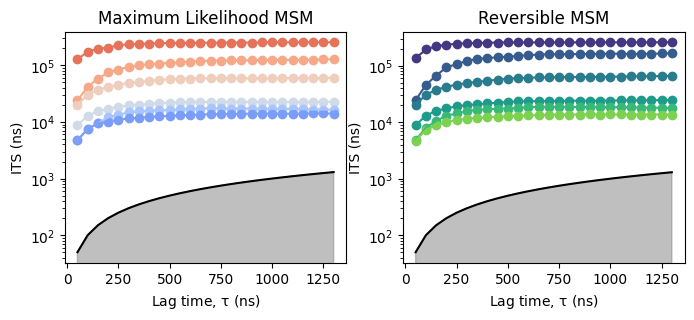

In [276]:
import deeptime
from deeptime.markov.msm import MaximumLikelihoodMSM
from deeptime.util.validation import ck_test
from deeptime.markov.msm import BayesianMSM
from deeptime.plots import plot_implied_timescales
from deeptime.util.validation import implied_timescales

from writhe_tools.msm_tools import MarkovModel, mfpt_mat
from writhe_tools.utils import one_hot
macrostates = np.load('1aa_cg_macrostates.npy')

mode =lambda x : np.bincount(x).argmax()

counter = lambda x, lag : deeptime.markov.TransitionCountEstimator(lagtime=int(lag),
                                                                   count_mode="sliding",
                                                
                                                                   
                                                                   ).fit(x, ignore_counting_mode=True).fetch_model()


from writhe_tools.utils import zero_index
def lump_states(dtraj, merge):
    merge = np.asarray(merge) if isinstance(merge, list) else merge
    new = np.copy(dtraj)
    idx = min(merge)
    new[isin_index(dtraj, merge)] = idx
    return zero_index(new)(new).astype(int)
    
    
def mfpt_mat(tmat, sets, dt=1, lag=1, mu=None):
    nstates = len(sets)
    mfpt = np.zeros((nstates, nstates))
    for i in range(nstates):
        for j in range(nstates):
            mfpt[i, j] = deeptime.markov.tools.analysis.mfpt(tmat, target=sets[j], origin=sets[i],  mu=mu)

    return mfpt * dt * lag

def tmat(dtraj, lag, norm=True):
    delta = one_hot(dtraj)
    C = delta[:-lag].T @ delta[lag:]
    return C / (C.sum(-1) if norm else 1)

    
def bayes_mfpt_matrix(bmsm,
                      sets,
                      ci=0.68):
    mfpt = np.zeros((len(sets), len(sets)))
    mfpt_err = np.zeros((len(sets), len(sets)))
    for i in range(len(sets)):
        for j in range(len(sets)):
            stats = bmsm.gather_stats("mfpt",
                                      A=sets[i],
                                      B=sets[j],
                                      confidence = ci
                                      )
            mfpt[i, j] = stats.mean
            mfpt_err[i, j] = (abs(stats.mean - stats.L) + abs(stats.mean - stats.R)) / 2
    
    return mfpt, mfpt_err

def bayes_mfpt(bmsm, i, j, ci: float=0.68):
    stats = bmsm.gather_stats("mfpt",
                              A=i,
                              B=j,
                              confidence=ci)
    err =  (abs(stats.mean - stats.L) + abs(stats.mean - stats.R)) / 2
    return stats.mean, err

def flux_matrix(sample, metastable_sets):
    nsets = len(metastable_sets)
    matrix = np.zeros((nsets, nsets))
    for i in range(nsets):
        for j in range(nsets):
            if i != j:
                matrix[i, j] = sample.reactive_flux(metastable_sets[i].astype(int), metastable_sets[j].astype(int)).total_flux
    return matrix

def bayes_pi(assignments, bayes):
    stats = bayes.gather_stats('stationary_distribution')
    dL, dR = (stats.mean - stats.L) ** 2, (stats.mean - stats.R) ** 2
    reduction = lambda x : np.sqrt(x.sum())
    err = (group_by(assignments, dL, reduction) + group_by(assignments, dR, reduction)) / 2
    return group_by(assignments, stats.mean, np.sum), err

# to rerun

# increase tCCA lag time for longer lag time MSM (doesn't visibly change the FES)

tcca = tCCA(writhe_features, lag=5, dim=50, epsilon=1e-8).fit()
proj = tcca.transform()
dtraj = Kmeans(proj,
               80, 
               2,
               max_iter=500)[0]

#dtraj = np.load('best_micro_dtraj_1aa.npy')
#micro_centroids = group_by(dtraj, proj[:, :2], partial(np.mean, axis=0))
assignments, micro_index = group_by(dtraj, macrostates, mode, return_keys=True)
#assignments = assign_to_centers(micro_centroids, centroids)
sets = group_by(assignments, np.arange(np.unique(dtraj).size))


#dtraj = np.load('best_micro_dtraj_1aa.npy')
lag, steps = 50, 25
lags = np.arange(1, steps + 1) * lag

# regular msm estimation
msm = MarkovModel(dtraj, 1).estimate_msm(lag, steps, reversible=False)
msm_rev =  MarkovModel(msm.dtraj).estimate_msm(lag, steps, reversible=True)

fig, ax = plt.subplots(1,
                       2, 
                       figsize=(8, 3),
                       sharey=False,
                      )
ax=ax.flat
msm.its('msm',
        n_its=6, 
        ax=ax[0],
        cmap='coolwarm_r',
        yscale='log'
       )

msm_rev.its('msm',
            n_its=6,
            ax=ax[1],
           )

# msm.its('msm',
#         n_its=6, 
#         ax=ax[2],
#         cmap='coolwarm_r',
#         yscale='linear'
#        )

# msm_rev.its('msm',
#             n_its=6,
#             ax=ax[3],
#             yscale='linear'
#            )

ax[0].set_title('Maximum Likelihood MSM')
ax[1].set_title('Reversible MSM')
# ax[2].set_title('')
# ax[3].set_title('')
#ax[0].set_ylim(1000, 50000)

# # bayes = [BayesianMSM(n_samples=500, reversible=True).fit(counter(dtraj, l)).fetch_model() for l in lags]
# # save_dict('1aa_bayes.pkl', bayes)

#bayes = load_dict('1aa_bayes.pkl')

# ensure lags and steps match the loaded bayes models
# lag = bayes[0].lagtime
# steps = len(bayes)
# lags = [i.lagtime for i in bayes]

In [271]:
mode =lambda x : np.bincount(x).argmax()

counter = lambda x, lag : deeptime.markov.TransitionCountEstimator(lagtime=int(lag),
                                                                   count_mode="effective",
                                                                   ).fit(x, ignore_counting_mode=True).fetch_model()

In [282]:
bayes = [BayesianMSM(n_samples=50,
                     reversible=False,
                     #stationary_distribution_constraint=group_by(dtraj, reduction=lambda x : np.sum(x) / len(dtraj)),
                    ).fit_from_discrete_timeseries(dtraj,
                                                   l,
                                                   count_mode='effective',
                                                   ignore_counting_mode=True
                                                  ).fetch_model()
    #fit(counter(dtraj, l), ignore_counting_mode=True)
    
         for l in lags]

Text(0.5, -0.03, 'Lag time (steps)')

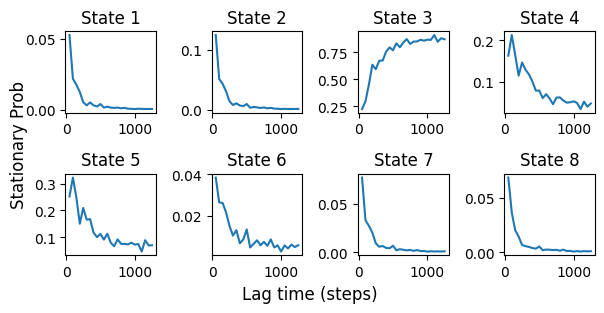

In [306]:
pops = np.stack([bayes_pi(assignments, bayes[i])[0] for i in range(len(lags))])
fig, axes = plt.subplots(2, 4, figsize=(6, 3), )
for j, (i,ax) in enumerate(zip(pops.T, axes.flat)):
    ax.plot(lags, i)
    ax.set_title(f"State {j+1}")
fig.tight_layout()
fig.supylabel("Stationary Prob", x=0)
fig.supxlabel("Lag time (steps)", y=-0.03)

Text(0.5, 1.03, '1aa')

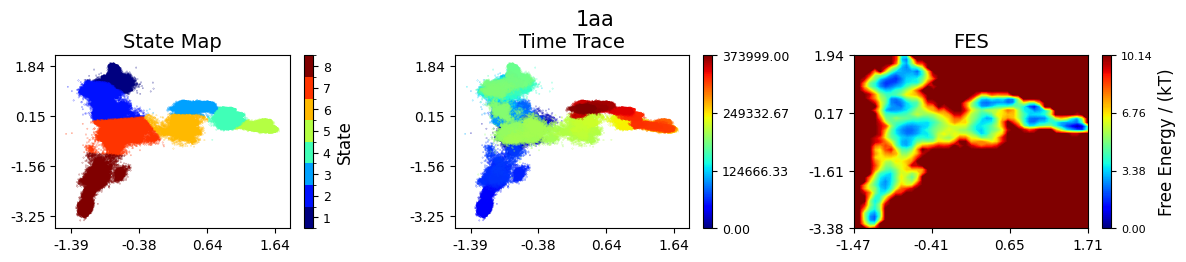

In [303]:
fig, axes = plt.subplots(1, 3, figsize=(12, 2.5))

proj2d(proj[:, :2], c = macrostates, ax=axes[0], state_map=True, dot_size=0.025, title='State Map')
proj2d(proj[:, :2], c = np.arange(len(proj)), ax=axes[1], title='Time Trace', dot_size=0.025)
fes2d(proj[:, :2], bins=45, ax=axes[2], mask=False, title='FES')
fig.tight_layout()
fig.suptitle('1aa', y=1.03, fontsize=15)

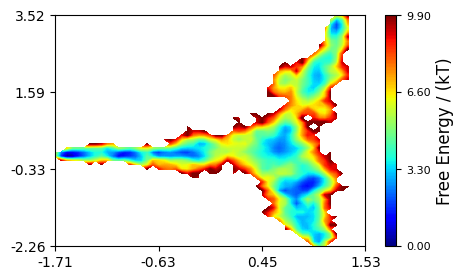

In [218]:
fes2d(proj[:,:2], bins=55)

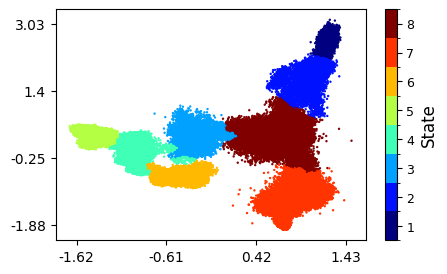

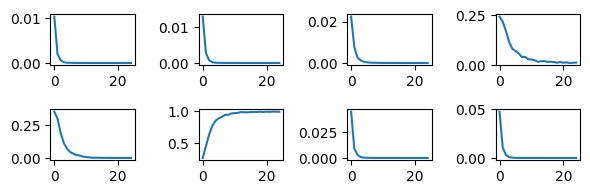

In [273]:
import pygpcca as gp
P = bayes[10].gather_stats('transition_matrix').mean
pcca = gp.GPCCA(P, z='LM', method='brandts')
pcca.optimize(8)
proj2d(proj[:,:2], pcca.macrostate_assignment[dtraj], state_map=True)
pops = np.stack([bayes_pi(pcca.macrostate_assignment, bayes[i])[0] for i in range(len(lags))])
fig, axes = plt.subplots(2, 4, figsize=(6, 2), )
for i,ax in zip(pops.T, axes.flat):
    ax.plot(i)
fig.tight_layout()
#bayes_pi(pcca.macrostate_assignment, bayes[10])

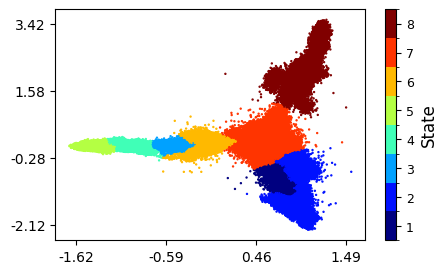

In [253]:
proj2d(proj[:,:2], assignments[dtraj], state_map=True)

In [58]:
lag, steps = 50, 30
lags = np.arange(1, steps + 1) * lag

In [226]:
# parameter scan
#np.save('best_micro_dtraj_epi.npy', dtraj)

# dtraj = np.load('best_micro_dtraj_apo.npy')
lag, steps = 50, 20
lags = np.arange(1, steps + 1) * lag

for tcca_lag in [100, 150, 200, 250, 300, 350, 400, 450, 500]:
    tcca = tCCA(writhe_features, lag=tcca_lag, dim=50, epsilon=1e-6).fit()
    proj = tcca.transform()
    for n_clusters in [50, 100, 150, 200, 250, 300, 350, 400, 500]:
        for ndim in [2, 3, 4, 5 ,8]:

            try:

                dtraj = Kmeans(proj, n_clusters, ndim, max_iter=500)[0]
                # regular msm estimation
                msm = MarkovModel(dtraj, 1).estimate_msm(lag, steps, reversible=False)
                sets = group_by(*group_by(msm.dtraj, macrostates, mode, return_keys=True))
                msm_rev =  MarkovModel(msm.dtraj).estimate_msm(lag, steps, reversible=True)
                
                fig, ax = plt.subplots(1, 2, figsize=(8, 3))
                msm.its('msm', n_its=6, ax=ax[0], cmap='coolwarm_r')
                msm_rev.its('msm', n_its=6, ax=ax[1])
                ax[0].set_title('Maximum Likelihood MSM')
                ax[1].set_title('Reversible MSM')
                fig.suptitle(f'tcca lag : {tcca_lag}, n_clusters : {n_clusters}, ndim : {ndim}', y=1.03)

            except:
                pass


KeyboardInterrupt



Error in callback <function _draw_all_if_interactive at 0x7f8b417f1990> (for post_execute), with arguments args (),kwargs {}:



KeyboardInterrupt



Error in callback <function flush_figures at 0x7f8a762a3b50> (for post_execute), with arguments args (),kwargs {}:



KeyboardInterrupt



In [524]:
ns = np.unique(macrostates).size
dict(zip(np.arange(1, ns+1), [np.fromiter(map(len, contiguous_bool(bools=macrostates == i)), int).mean()
                       for i in range(ns)]))

{1: 17.994145199063233,
 2: 40.663961813842484,
 3: 161.11917098445596,
 4: 122.9943342776204,
 5: 269.02150537634407,
 6: 69.94779116465864,
 7: 90.1608040201005,
 8: 348.2429906542056}

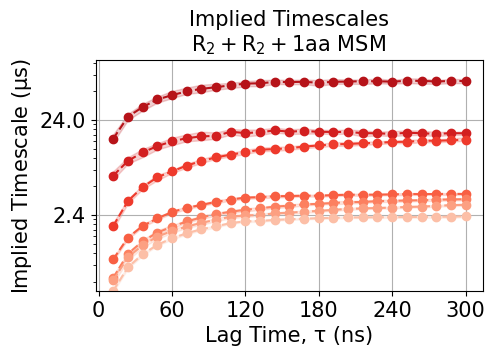

In [262]:

from writhe_tools.utils import symbols
import matplotlib.ticker as ticker

its = implied_timescales(bayes)
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
ax.set_yscale("log")
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x * 0.24e-3:.1f}"))
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x * 0.24:.0f}"))
plot_implied_timescales(its,
                        ax=ax,
                        colors = get_color_list(7, 'Reds_r', 60, 45),
                        n_its=7,
                        show_mle=False)
#ax.set_xticks(np.arange(len(lags)), np.round(lags * .24, 1))
#ax.set_xlim(5, 15)
ax.set_ylabel(r"Implied Timescale ($\mu$s)", size=15)
ax.set_xlabel(f"Lag Time, {symbols('tau')} (ns)", size=15)
plt.title('Implied Timescales\n' + r"$R_{2} + R_{2} + 1aa$ MSM ",size = 15)
ax.tick_params('both', labelsize = 15)
ax.tick_params('x', labelsize = 15)
#ax.set_xlim(12, 240)
ax.set_ylim(1600,)
ax.grid()

In [48]:
save_dict('1aa_its.pkl', its)

In [367]:
group_by(cg, reduction=lambda x : np.sum(x) / len(cg)) * 100

array([ 8.21764706, 13.80828877,  8.97005348,  8.3144385 , 11.60882353,
       20.06871658,  4.65695187, 14.39197861,  9.9631016 ])

In [10]:
cg = lump_states(macrostates, [0, 1])
# fes2d(proj[:, :2], cluster_centers=group_by(macrostates.astype(int), proj[:, :2], partial(np.mean, axis=0)))
# fes2d(proj[:, :2], cluster_centers=group_by(cg.astype(int), proj[:, :2], partial(np.mean, axis=0)))
cg = lump_states(cg, [3, 4])
#fes2d(proj[:, :2], cluster_centers=group_by(cg.astype(int), proj[:, :2], partial(np.mean, axis=0)))
cg = lump_states(cg, [9, 10])
# fes2d(proj[:, :2], cluster_centers=group_by(cg.astype(int), proj[:, :2], partial(np.mean, axis=0)),
#      bins=55)
cg = lump_states(cg, [4,5])
# fes2d(proj[:, :2], cluster_centers=group_by(cg.astype(int), proj[:, :2], partial(np.mean, axis=0)),
#      bins=55)

cg = lump_states(cg, [2,1])
# fes2d(proj[:, :2], cluster_centers=group_by(cg.astype(int), proj[:, :2], partial(np.mean, axis=0)),
#      bins=55)


# cg = lump_states(cg, [3, 4])
# fes2d(proj[:, :2], cluster_centers=group_by(cg.astype(int), proj[:, :2], partial(np.mean, axis=0)),
#      bins=55)


In [9]:
np.save('1aa_cg_macrostates.npy', cg)

In [118]:
msm_index = 5
mfpt_mean, mfpt_error = bayes_mfpt_matrix(bayes[msm_index], sets)
flux = np.stack([flux_matrix(i, sets) for i in bayes[msm_index].samples])
flux /= flux.sum(2, keepdims=True)
flux_mu = flux.mean(0)
flux_err = np.diff(np.percentile(flux, [2.5, 97.5], axis=0), axis=0).squeeze() / 2 

<Axes: title={'center': 'R2 + R2 + 1aa MSM Macrostate Flux Matrix'}, xlabel='$State_{i}$'>

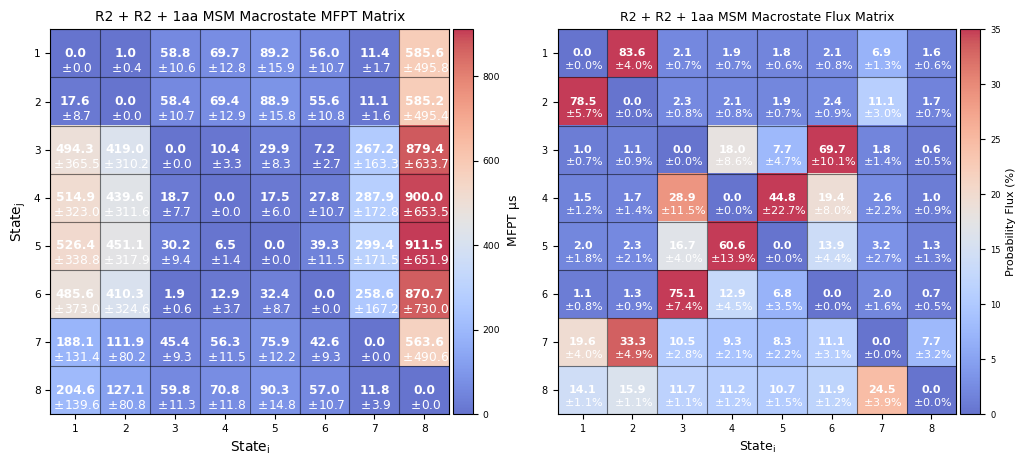

In [119]:
fig, axes = plt.subplots(1, 2, figsize = (12, 5))


annotated_matrix_plot(mfpt_mean * 0.24e-3,
                      mfpt_error * 0.24e-3,
                      decimals=1,
                      cmap='coolwarm', 
                      alpha=.78,
                      title = r"R2 + R2 + 1aa MSM Macrostate MFPT Matrix",
                      font_scale=.22,
                      cbar_label= r" MFPT $\mu$s",
                      grid=True, 
                      grid_alpha=.3, 
                      ax=axes[0],

                      )

annotated_matrix_plot(flux_mu * 100,
                      flux_err * 100,
                      decimals=1,
                      cmap='coolwarm', 
                      alpha=.78,
                      font_scale=.2,
                      title = r"R2 + R2 + 1aa MSM Macrostate Flux Matrix",
                      unit = "%",
                      cbar_label = r"Probability Flux (%)",
                      grid=True, 
                      grid_alpha=.3, 
                      ax=axes[1], 
                      vmax=35, ylabel='',
                      )

<Axes: title={'center': 'Stationary Distribution'}, xlabel='State', ylabel='Population'>

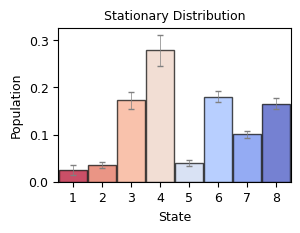

In [144]:
mu, err = bayes_pi(pcca.macrostate_assignment, bayes[0])
box_plot(mu, err,
         ylabel='Population',
         xlabel='State',
         cmap='coolwarm_r',
         figsize=(3, 2),
         font_scale=1.5,
         error_capsize=2.5,
         title = 'Stationary Distribution', 
         alpha=.7
         
        )

In [95]:
unitcell_lengths

array([[10.898814, 10.898814, 10.898814],
       [10.905341, 10.905341, 10.905341],
       [10.895957, 10.895957, 10.895957],
       ...,
       [10.911324, 10.911324, 10.911324],
       [10.913614, 10.913614, 10.913614],
       [10.90941 , 10.90941 , 10.90941 ]], dtype=float32)

<Axes: title={'center': 'Stationary Distribution'}, xlabel='State', ylabel='Population'>

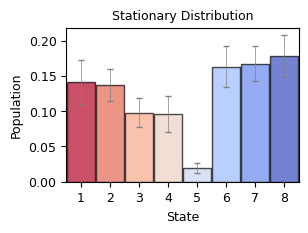

In [98]:
mu, err = bayes_pi(assignments, bayes[-5])
box_plot(mu, err,
         ylabel='Population',
         xlabel='State',
         cmap='coolwarm_r',
         figsize=(3, 2),
         font_scale=1.5,
         error_capsize=2.5,
         title = 'Stationary Distribution', 
         alpha=.7
         
        )

<Axes: title={'center': 'Stationary Distribution'}, xlabel='State', ylabel='Population'>

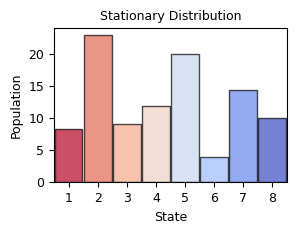

In [140]:
box_plot(group_by(assignments[dtraj], reduction = lambda x : 100 * x.sum() / dtraj.size),
         ylabel='Population',
         xlabel='State',
         cmap='coolwarm_r',
         figsize=(3, 2),
         font_scale=1.5,
         error_capsize=2.5,
         title = 'Stationary Distribution', 
         alpha=.7
         
        )

In [49]:
import numpy as np
import pandas as pd
import mdtraj as md

def pbc_distance_sanity(traj):
    """
    One-call PBC/distance sanity test for a trajectory containing two proteins + ligand.

    Usage:
        report = pbc_distance_sanity(traj)

    It auto-detects:
        - two largest protein chains
        - likely ligand atoms
        - protein/ligand bonded distances
        - sampled protein-ligand and protein-protein distance pairs

    The main red flags are:
        - missing/bad unit cell
        - bonded distances that jump even with periodic=True
        - ligand internal distances that jump
        - protein-ligand sampled distances with extreme PBC jumps/contact flickering
    """

    # -------------------------
    # user-editable constants
    # -------------------------
    FRAME_CHUNK = 2000
    PAIR_CHUNK = 1000
    MAX_AUTO_INTER_PAIRS = 8000
    MAX_AUTO_INTERNAL_PAIRS = 5000
    CONTACT_CUTOFF_NM = 0.6
    BONDED_JUMP_WARN_NM = 0.05
    BONDED_MAX_WARN_NM = 0.25
    FEATURE_JUMP_WARN_NM = 0.35
    RAW_MINUS_PBC_WARN_NM = 1.0
    SEED = 0

    ion_resnames = {
        "NA", "CL", "K", "CA", "MG", "ZN", "MN", "FE", "CU", "CO",
        "CD", "NI", "CS", "RB", "LI", "F", "BR", "IOD", "CLA", "SOD"
    }

    rng = np.random.default_rng(SEED)
    top = traj.topology

    def show(df, n=25):
        try:
            display(df.head(n))
        except Exception:
            print(df.head(n).to_string(index=False))

    def atom_label(i):
        a = top.atom(int(i))
        r = a.residue
        c = r.chain
        return f"{i}:{a.name}-{r.name}{r.resSeq}-chain{c.index}"

    def is_heavy(atom_index):
        a = top.atom(int(atom_index))
        if a.element is not None:
            return a.element.symbol != "H"
        return not a.name.upper().startswith("H")

    def protein_chain_atoms():
        chains = []
        for chain in top.chains:
            atoms = []
            for atom in chain.atoms:
                if atom.residue.is_protein:
                    atoms.append(atom.index)
            if len(atoms) > 0:
                chains.append((chain.index, np.asarray(atoms, dtype=int)))
        chains = sorted(chains, key=lambda x: len(x[1]), reverse=True)
        return chains

    def likely_ligand_atoms():
        residues = []
        for res in top.residues:
            if res.is_protein:
                continue
            if res.is_water:
                continue
            if res.name.upper() in ion_resnames:
                continue

            atoms = np.asarray([a.index for a in res.atoms], dtype=int)
            if len(atoms) >= 2:
                residues.append((res.name, res.index, atoms))

        if len(residues) == 0:
            return np.asarray([], dtype=int), []

        # In a two-protein + one-ligand system, this usually grabs the ligand.
        # If there are multiple non-water/non-protein residues, keep all of them,
        # but report what was detected.
        lig_atoms = np.concatenate([x[2] for x in residues])
        return lig_atoms.astype(int), residues

    def bonds_inside(atom_indices):
        atom_set = set(np.asarray(atom_indices, dtype=int))
        pairs = []
        for a, b in top.bonds:
            if a.index in atom_set and b.index in atom_set:
                pairs.append((a.index, b.index))
        return np.asarray(pairs, dtype=int)

    def ca_neighbor_pairs(atom_indices):
        atom_set = set(np.asarray(atom_indices, dtype=int))
        cas = []
        for atom in top.atoms:
            if atom.index in atom_set and atom.residue.is_protein and atom.name == "CA":
                cas.append((atom.residue.index, atom.index))
        cas = sorted(cas)
        pairs = []
        for (_, i), (_, j) in zip(cas[:-1], cas[1:]):
            pairs.append((i, j))
        return np.asarray(pairs, dtype=int)

    def sample_inter_pairs(atoms_a, atoms_b, max_pairs):
        atoms_a = np.asarray([i for i in atoms_a if is_heavy(i)], dtype=int)
        atoms_b = np.asarray([i for i in atoms_b if is_heavy(i)], dtype=int)

        if len(atoms_a) == 0 or len(atoms_b) == 0:
            return np.empty((0, 2), dtype=int)

        total = len(atoms_a) * len(atoms_b)

        if total <= max_pairs:
            aa, bb = np.meshgrid(atoms_a, atoms_b, indexing="ij")
            return np.column_stack([aa.ravel(), bb.ravel()]).astype(int)

        ai = rng.integers(0, len(atoms_a), size=max_pairs * 2)
        bi = rng.integers(0, len(atoms_b), size=max_pairs * 2)
        pairs = np.column_stack([atoms_a[ai], atoms_b[bi]])
        pairs = np.unique(pairs, axis=0)

        if len(pairs) > max_pairs:
            keep = rng.choice(len(pairs), size=max_pairs, replace=False)
            pairs = pairs[keep]

        return pairs.astype(int)

    def sample_internal_pairs(atoms, max_pairs):
        atoms = np.asarray([i for i in atoms if is_heavy(i)], dtype=int)
        n = len(atoms)

        if n < 2:
            return np.empty((0, 2), dtype=int)

        total = n * (n - 1) // 2

        if total <= max_pairs:
            pairs = []
            for a in range(n):
                for b in range(a + 1, n):
                    pairs.append((atoms[a], atoms[b]))
            return np.asarray(pairs, dtype=int)

        pairs = []
        seen = set()
        while len(pairs) < max_pairs and len(seen) < total:
            a = rng.integers(0, n)
            b = rng.integers(0, n)
            if a == b:
                continue
            i, j = sorted((atoms[a], atoms[b]))
            key = (int(i), int(j))
            if key not in seen:
                seen.add(key)
                pairs.append(key)

        return np.asarray(pairs, dtype=int)

    def unitcell_report():
        print("\n" + "=" * 80)
        print("UNIT CELL CHECK")
        print("=" * 80)

        if traj.unitcell_lengths is None:
            print("FAIL: traj.unitcell_lengths is None. PBC distances are not trustworthy.")
            return pd.DataFrame()

        lengths = np.asarray(traj.unitcell_lengths)

        rows = []
        for k, name in enumerate(["a", "b", "c"]):
            rows.append({
                "box_axis": name,
                "min_nm": np.nanmin(lengths[:, k]),
                "median_nm": np.nanmedian(lengths[:, k]),
                "max_nm": np.nanmax(lengths[:, k]),
                "std_nm": np.nanstd(lengths[:, k]),
            })

        df = pd.DataFrame(rows)
        show(df, n=10)

        bad = ~np.isfinite(lengths).all(axis=1)
        zero = (lengths <= 0).any(axis=1)

        if bad.any():
            print("FAIL: non-finite unit-cell lengths at frames:", np.where(bad)[0][:20])

        if zero.any():
            print("FAIL: zero/negative unit-cell lengths at frames:", np.where(zero)[0][:20])

        if traj.n_frames > 1:
            box_jump = np.linalg.norm(np.diff(lengths, axis=0), axis=1)
            worst = np.argsort(box_jump)[::-1][:10]
            jump_df = pd.DataFrame({
                "frame_start": worst,
                "frame_end": worst + 1,
                "box_jump_nm": box_jump[worst],
            })
            print("\nLargest box jumps:")
            show(jump_df, n=10)

        return df

    def distance_report(
        pairs,
        name,
        jump_warn_nm,
        max_warn_nm=None,
        contact_cutoff_nm=None,
        raw_minus_pbc_warn_nm=RAW_MINUS_PBC_WARN_NM,
    ):
        print("\n" + "=" * 80)
        print(name)
        print("=" * 80)

        pairs = np.asarray(pairs, dtype=int)

        if len(pairs) == 0:
            print("No pairs available.")
            return pd.DataFrame()

        n_pairs = len(pairs)
        n_frames = traj.n_frames

        max_pbc = np.full(n_pairs, -np.inf)
        min_pbc = np.full(n_pairs, np.inf)
        sum_pbc = np.zeros(n_pairs)

        max_raw = np.full(n_pairs, -np.inf)
        max_raw_minus_pbc = np.zeros(n_pairs)

        max_pbc_jump = np.zeros(n_pairs)
        worst_jump_frame_start = np.full(n_pairs, -1, dtype=int)

        contact_sum = np.zeros(n_pairs)
        contact_flips = np.zeros(n_pairs)

        for p0 in range(0, n_pairs, PAIR_CHUNK):
            p1 = min(p0 + PAIR_CHUNK, n_pairs)
            pp = pairs[p0:p1]

            prev_d = None
            prev_contact = None

            for f0 in range(0, n_frames, FRAME_CHUNK):
                f1 = min(f0 + FRAME_CHUNK, n_frames)
                t = traj[f0:f1]

                try:
                    d_pbc = md.compute_distances(t, pp, periodic=True, opt=True)
                except Exception as e:
                    print(f"FAIL during PBC distance calculation in {name}: {repr(e)}")
                    return pd.DataFrame()

                d_raw = md.compute_distances(t, pp, periodic=False, opt=True)

                local = slice(p0, p1)

                max_pbc[local] = np.maximum(max_pbc[local], d_pbc.max(axis=0))
                min_pbc[local] = np.minimum(min_pbc[local], d_pbc.min(axis=0))
                sum_pbc[local] += d_pbc.sum(axis=0)

                max_raw[local] = np.maximum(max_raw[local], d_raw.max(axis=0))
                max_raw_minus_pbc[local] = np.maximum(
                    max_raw_minus_pbc[local],
                    np.abs(d_raw - d_pbc).max(axis=0),
                )

                if len(d_pbc) > 1:
                    jumps = np.abs(np.diff(d_pbc, axis=0))
                    local_max_jump = jumps.max(axis=0)
                    local_arg_jump = jumps.argmax(axis=0) + f0

                    update = local_max_jump > max_pbc_jump[local]
                    idx = np.where(update)[0]
                    max_pbc_jump[p0:p1][idx] = local_max_jump[idx]
                    worst_jump_frame_start[p0:p1][idx] = local_arg_jump[idx]

                if prev_d is not None:
                    cross_jump = np.abs(d_pbc[0] - prev_d)
                    update = cross_jump > max_pbc_jump[local]
                    idx = np.where(update)[0]
                    max_pbc_jump[p0:p1][idx] = cross_jump[idx]
                    worst_jump_frame_start[p0:p1][idx] = f0 - 1

                prev_d = d_pbc[-1].copy()

                if contact_cutoff_nm is not None:
                    contact = d_pbc < contact_cutoff_nm
                    contact_sum[local] += contact.sum(axis=0)

                    if len(contact) > 1:
                        contact_flips[local] += np.abs(np.diff(contact.astype(np.int8), axis=0)).sum(axis=0)

                    if prev_contact is not None:
                        contact_flips[local] += np.abs(contact[0].astype(np.int8) - prev_contact.astype(np.int8))

                    prev_contact = contact[-1].copy()

        mean_pbc = sum_pbc / max(n_frames, 1)

        rows = []
        for k, (i, j) in enumerate(pairs):
            row = {
                "pair_index": k,
                "atom_i": int(i),
                "atom_j": int(j),
                "label_i": atom_label(i),
                "label_j": atom_label(j),
                "min_pbc_nm": min_pbc[k],
                "mean_pbc_nm": mean_pbc[k],
                "max_pbc_nm": max_pbc[k],
                "max_raw_nm": max_raw[k],
                "max_raw_minus_pbc_nm": max_raw_minus_pbc[k],
                "max_pbc_jump_nm": max_pbc_jump[k],
                "worst_jump_frame_start": int(worst_jump_frame_start[k]),
                "worst_jump_frame_end": int(worst_jump_frame_start[k] + 1) if worst_jump_frame_start[k] >= 0 else -1,
            }

            if contact_cutoff_nm is not None:
                row["contact_fraction"] = contact_sum[k] / max(n_frames, 1)
                row["contact_flip_fraction"] = contact_flips[k] / max(n_frames - 1, 1)

            rows.append(row)

        df = pd.DataFrame(rows)

        print("n_pairs:", len(df))
        print("largest PBC distance:", df["max_pbc_nm"].max())
        print("largest PBC jump:", df["max_pbc_jump_nm"].max())
        print("largest raw-minus-PBC gap:", df["max_raw_minus_pbc_nm"].max())

        print("\nWorst PBC jumps:")
        show(df.sort_values("max_pbc_jump_nm", ascending=False), n=20)

        flags = df[df["max_pbc_jump_nm"] > jump_warn_nm].copy()

        if max_warn_nm is not None:
            flags = pd.concat([flags, df[df["max_pbc_nm"] > max_warn_nm]], axis=0).drop_duplicates("pair_index")

        if raw_minus_pbc_warn_nm is not None:
            # This alone is not always bad, but useful to see.
            pass

        print("\nFlagged by current thresholds:")
        if len(flags) == 0:
            print("None.")
        else:
            show(flags.sort_values("max_pbc_jump_nm", ascending=False), n=30)

        if contact_cutoff_nm is not None:
            print("\nWorst contact flickering:")
            show(df.sort_values("contact_flip_fraction", ascending=False), n=20)

        return df

    # ------------------------------------------------------------------
    # Run checks
    # ------------------------------------------------------------------

    reports = {}

    reports["unitcell"] = unitcell_report()

    chains = protein_chain_atoms()
    lig_atoms, lig_residues = likely_ligand_atoms()

    print("\n" + "=" * 80)
    print("AUTO-DETECTED SYSTEM PARTS")
    print("=" * 80)

    if len(chains) < 2:
        print("FAIL: fewer than two protein chains detected.")
        print("Detected protein chains:", [(ci, len(a)) for ci, a in chains])
        return reports

    chain1_id, p1_atoms = chains[0]
    chain2_id, p2_atoms = chains[1]

    print(f"protein 1: chain {chain1_id}, atoms {len(p1_atoms)}")
    print(f"protein 2: chain {chain2_id}, atoms {len(p2_atoms)}")

    if len(lig_atoms) == 0:
        print("WARNING: no likely ligand atoms detected.")
    else:
        print(f"likely ligand atoms: {len(lig_atoms)}")
        print("likely ligand residues:")
        for resname, residx, atoms in lig_residues:
            print(f"  residue_index={residx}, resname={resname}, n_atoms={len(atoms)}")

    # Protein bonded checks
    p1_bonds = bonds_inside(p1_atoms)
    p2_bonds = bonds_inside(p2_atoms)

    if len(p1_bonds) == 0:
        print("\nWARNING: no topology bonds found for protein 1. Falling back to neighboring CA distances.")
        p1_bonds = ca_neighbor_pairs(p1_atoms)

    if len(p2_bonds) == 0:
        print("\nWARNING: no topology bonds found for protein 2. Falling back to neighboring CA distances.")
        p2_bonds = ca_neighbor_pairs(p2_atoms)

    reports["protein1_bonded_or_CA"] = distance_report(
        p1_bonds,
        name="PROTEIN 1 BONDED / CA-NEIGHBOR DISTANCES",
        jump_warn_nm=BONDED_JUMP_WARN_NM,
        max_warn_nm=BONDED_MAX_WARN_NM,
        contact_cutoff_nm=None,
    )

    reports["protein2_bonded_or_CA"] = distance_report(
        p2_bonds,
        name="PROTEIN 2 BONDED / CA-NEIGHBOR DISTANCES",
        jump_warn_nm=BONDED_JUMP_WARN_NM,
        max_warn_nm=BONDED_MAX_WARN_NM,
        contact_cutoff_nm=None,
    )

    # Ligand internal checks
    if len(lig_atoms) > 0:
        lig_bonds = bonds_inside(lig_atoms)

        if len(lig_bonds) > 0:
            reports["ligand_bonded"] = distance_report(
                lig_bonds,
                name="LIGAND BONDED DISTANCES",
                jump_warn_nm=BONDED_JUMP_WARN_NM,
                max_warn_nm=BONDED_MAX_WARN_NM,
                contact_cutoff_nm=None,
            )
        else:
            print("\nWARNING: no topology bonds found for ligand. Using sampled ligand internal distances.")
            lig_internal = sample_internal_pairs(lig_atoms, MAX_AUTO_INTERNAL_PAIRS)
            reports["ligand_internal_sampled"] = distance_report(
                lig_internal,
                name="LIGAND INTERNAL SAMPLED DISTANCES",
                jump_warn_nm=0.15,
                max_warn_nm=None,
                contact_cutoff_nm=None,
            )

        # Protein-ligand sampled feature-like checks
        p1_lig_pairs = sample_inter_pairs(p1_atoms, lig_atoms, MAX_AUTO_INTER_PAIRS)
        p2_lig_pairs = sample_inter_pairs(p2_atoms, lig_atoms, MAX_AUTO_INTER_PAIRS)

        reports["protein1_ligand_sampled"] = distance_report(
            p1_lig_pairs,
            name="PROTEIN 1 - LIGAND SAMPLED DISTANCES",
            jump_warn_nm=FEATURE_JUMP_WARN_NM,
            max_warn_nm=None,
            contact_cutoff_nm=CONTACT_CUTOFF_NM,
        )

        reports["protein2_ligand_sampled"] = distance_report(
            p2_lig_pairs,
            name="PROTEIN 2 - LIGAND SAMPLED DISTANCES",
            jump_warn_nm=FEATURE_JUMP_WARN_NM,
            max_warn_nm=None,
            contact_cutoff_nm=CONTACT_CUTOFF_NM,
        )

    # Protein-protein sampled checks
    p1_p2_pairs = sample_inter_pairs(p1_atoms, p2_atoms, MAX_AUTO_INTER_PAIRS)

    reports["protein1_protein2_sampled"] = distance_report(
        p1_p2_pairs,
        name="PROTEIN 1 - PROTEIN 2 SAMPLED DISTANCES",
        jump_warn_nm=FEATURE_JUMP_WARN_NM,
        max_warn_nm=None,
        contact_cutoff_nm=CONTACT_CUTOFF_NM,
    )

    # Summary
    print("\n" + "=" * 80)
    print("SUMMARY")
    print("=" * 80)

    summary_rows = []
    for key, df in reports.items():
        if not isinstance(df, pd.DataFrame) or len(df) == 0:
            continue

        if "max_pbc_jump_nm" not in df.columns:
            continue

        summary_rows.append({
            "check": key,
            "n_pairs": len(df),
            "max_pbc_jump_nm": df["max_pbc_jump_nm"].max(),
            "n_pairs_jump_gt_0.05_nm": int((df["max_pbc_jump_nm"] > 0.05).sum()),
            "n_pairs_jump_gt_0.15_nm": int((df["max_pbc_jump_nm"] > 0.15).sum()),
            "n_pairs_jump_gt_0.35_nm": int((df["max_pbc_jump_nm"] > 0.35).sum()),
            "max_raw_minus_pbc_nm": df["max_raw_minus_pbc_nm"].max(),
        })

    summary = pd.DataFrame(summary_rows)
    reports["summary"] = summary
    show(summary, n=50)

    print("\nInterpretation:")
    print("- If bonded/CA-neighbor PBC distances jump, the trajectory/topology/box is broken badly enough to ruin distances.")
    print("- If ligand internal distances jump, the ligand/topology/imaging is suspect.")
    print("- If only raw distances jump but PBC distances are smooth, ugly visualization is probably not the issue.")
    print("- If protein-ligand or protein-protein sampled distances have huge PBC jumps/contact flickering, your MSM features may be corrupted.")

    return reports

traj=md.load(ligand_files[1], top=ligand_pdbs[1])
# Only needed argument:
report = pbc_distance_sanity(traj)


UNIT CELL CHECK


,box_axis,min_nm,median_nm,max_nm,std_nm
0,a,10.887206,10.906068,10.927106,0.004289
1,b,10.887206,10.906068,10.927106,0.004289
2,c,10.887206,10.906068,10.927106,0.004289



Largest box jumps:


,frame_start,frame_end,box_jump_nm
0,40797,40798,0.047749
1,266136,266137,0.047143
2,214184,214185,0.046502
3,324012,324013,0.045598
4,42273,42274,0.044710
5,140289,140290,0.044652
6,12667,12668,0.043656
7,268404,268405,0.043590
8,328136,328137,0.043387
9,216474,216475,0.043277



AUTO-DETECTED SYSTEM PARTS
protein 1: chain 1, atoms 335
protein 2: chain 2, atoms 335
likely ligand atoms: 53
likely ligand residues:
  residue_index=0, resname=LIG, n_atoms=47
  residue_index=26, resname=NH2, n_atoms=3
  residue_index=52, resname=NH2, n_atoms=3

PROTEIN 1 BONDED / CA-NEIGHBOR DISTANCES
n_pairs: 339
largest PBC distance: 0.19767560064792633
largest PBC jump: 0.025623679161071777
largest raw-minus-PBC gap: 0.0

Worst PBC jumps:


,pair_index,atom_i,atom_j,label_i,label_j,min_pbc_nm,mean_pbc_nm,max_pbc_nm,max_raw_nm,max_raw_minus_pbc_nm,max_pbc_jump_nm,worst_jump_frame_start,worst_jump_frame_end
187,187,228,231,228:CB-CYS14-chain1,231:SG-CYS14-chain1,0.164905,0.181623,0.197676,0.197676,0.0,0.025624,39914,39915
39,39,86,88,86:CA-TYR3-chain1,88:CB-TYR3-chain1,0.139935,0.153904,0.170463,0.170463,0.0,0.024575,231077,231078
115,115,159,161,159:CA-ALA8-chain1,161:CB-ALA8-chain1,0.138605,0.153337,0.168554,0.168554,0.0,0.023816,80555,80556
143,143,189,195,189:CA-ALA11-chain1,195:C-ALA11-chain1,0.140623,0.154494,0.168158,0.168158,0.0,0.023738,141200,141201
304,304,346,348,346:CG-LEU22-chain1,348:CD1-LEU22-chain1,0.138534,0.153057,0.167557,0.167557,0.0,0.023437,282860,282861
248,248,287,289,287:N-ASP18-chain1,289:CA-ASP18-chain1,0.134562,0.147679,0.160867,0.160867,0.0,0.023140,147091,147092
42,42,88,91,88:CB-TYR3-chain1,91:CG-TYR3-chain1,0.136753,0.152011,0.166356,0.166356,0.0,0.023126,208649,208650
59,59,107,110,107:CA-GLY4-chain1,110:C-GLY4-chain1,0.137836,0.153437,0.168314,0.168314,0.0,0.023125,201622,201623
292,292,332,335,332:CB-SER21-chain1,335:OG-SER21-chain1,0.127446,0.141566,0.155794,0.155794,0.0,0.023032,72874,72875
66,66,114,121,114:CA-SER5-chain1,121:C-SER5-chain1,0.136825,0.153613,0.167853,0.167853,0.0,0.022964,98396,98397


... (21 outputs left out)

,pair_index,atom_i,atom_j,label_i,label_j,min_pbc_nm,mean_pbc_nm,max_pbc_nm,max_raw_nm,max_raw_minus_pbc_nm,max_pbc_jump_nm,worst_jump_frame_start,worst_jump_frame_end,contact_fraction,contact_flip_fraction
1001,1001,143,534,143:NE1-TRP7-chain1,534:O-ALA37-chain2,0.261751,1.991963,9.298015,18.999308,18.000021,1.990653,194984,194985,0.135872,0.082744
2129,2129,154,503,154:CD2-TRP7-chain1,503:C-ALA34-chain2,0.354199,1.994290,9.354792,18.974699,18.115290,2.157978,106326,106327,0.145134,0.079150
3919,3919,218,492,218:OE1-GLN13-chain1,492:CD2-TRP33-chain2,0.289153,2.145958,9.235155,18.937138,17.784815,1.849557,120022,120023,0.123465,0.076321
2497,2497,186,483,186:O-ALA10-chain1,483:CE2-TRP33-chain2,0.292981,2.002440,9.229614,18.771860,17.943111,2.192157,120022,120023,0.098059,0.074016
6577,6577,209,475,209:CA-GLN13-chain1,475:CB-TRP33-chain2,0.357420,2.062058,9.279449,18.392803,17.844311,1.821970,120022,120023,0.093332,0.073064
2068,2068,185,646,185:C-ALA10-chain1,646:CD1-LEU45-chain2,0.310322,1.978640,9.362801,19.052345,17.928604,1.953287,199899,199900,0.076489,0.072989
2235,2235,185,529,185:C-ALA10-chain1,529:CB-ALA37-chain2,0.329251,1.924898,9.334394,18.822872,17.882845,1.856842,197530,197531,0.157594,0.072086
244,244,132,527,132:O-ALA6-chain1,527:CA-ALA37-chain2,0.304808,1.972050,9.417188,18.530825,17.675091,1.714446,22532,22533,0.129896,0.071840
630,630,140,609,140:CG-TRP7-chain1,609:CZ-TYR42-chain2,0.331102,1.916918,9.250001,19.170013,18.402721,1.929698,194984,194985,0.097449,0.071342
3544,3544,150,424,150:CZ3-TRP7-chain1,424:CA-TYR29-chain2,0.333916,2.187854,9.357772,20.117065,18.163347,2.149731,106326,106327,0.110939,0.070840



SUMMARY


,check,n_pairs,max_pbc_jump_nm,n_pairs_jump_gt_0.05_nm,n_pairs_jump_gt_0.15_nm,n_pairs_jump_gt_0.35_nm,max_raw_minus_pbc_nm
0,protein1_bonded_or_CA,339,0.025624,0,0,0,0.000000
1,protein2_bonded_or_CA,339,0.025013,0,0,0,0.000000
2,ligand_bonded,4,0.000002,0,0,0,0.000000
3,protein1_ligand_sampled,4928,3.223372,4925,4924,4921,18.873373
4,protein2_ligand_sampled,4928,3.250213,4925,4924,4921,18.899427
5,protein1_protein2_sampled,8000,2.890758,8000,8000,8000,18.900826



Interpretation:
- If bonded/CA-neighbor PBC distances jump, the trajectory/topology/box is broken badly enough to ruin distances.
- If ligand internal distances jump, the ligand/topology/imaging is suspect.
- If only raw distances jump but PBC distances are smooth, ugly visualization is probably not the issue.
- If protein-ligand or protein-protein sampled distances have huge PBC jumps/contact flickering, your MSM features may be corrupted.


In [91]:
40 / (traj.shape[0] * 0.24e-3 ) * traj.shape[0]

166666.66666666666

In [90]:
(191056 / traj.shape[0]) * (traj.shape[0] * 0.24e-3 )

45.85344

In [92]:
(106326 / traj.shape[0]) * (traj.shape[0] * 0.24e-3 )

25.51824

In [93]:

( 13864 / traj.shape[0]) * (traj.shape[0] * 0.24e-3 )

3.3273600000000005

In [94]:
( 120023 / traj.shape[0]) * (traj.shape[0] * 0.24e-3 )

28.80552